# Karhutla: Segmentasi Area Terbakar dengan DINOv3 (timm) — Run All

Notebook ini berjalan dari awal sampai akhir tanpa campur tangan:

1. **Unduh data** — citra *saat* kebakaran + mask dari dataset BRIN (Landsat-8, 227 tile), lalu citra *sebelum* dan *sesudah* untuk lokasi yang sama dari Microsoft Planetary Computer (Landsat 8/9, tanpa login).
2. **Bentuk CSV** — `path_sebelum, path_saat, path_sesudah, lat, lon, tanggal_kebakaran` + kolom pendukung (tanggal tiap citra, % cerah, cuaca dari Open-Meteo).
3. **Modeling** — backbone **DINOv3** dari `timm` (dibekukan) + cabang spektral CNN + decoder U-Net.
4. **Evaluasi** — IoU/F1/precision/recall di data uji + gambar mask *saat kebakaran* dengan 3 level warna (merah = tinggi, oranye = sedang, kuning = ringan).
5. **Simpan model** + CSV + metrik + gambar ke `/kaggle/working/output`.
6. **Bangun `model.mar` (TorchServe) yang sudah berisi backbone DINOv3** → uji offline → **link unduhan**.

**Pengaturan Kaggle sebelum Run All:** *Settings → Internet: On*, *Accelerator: GPU T4 / P100*.

**Sumber dataset BRIN (dicek otomatis berurutan):**
1. Dataset yang kamu tambahkan lewat *Add Input* (folder apa pun di `/kaggle/input` yang berisi `*_mask.tif`) — **cara paling andal**: unduh zip dari https://data.mendeley.com/datasets/fs7mtkg2wk lalu unggah sekali sebagai Kaggle Dataset.
2. Unduh otomatis lewat API publik Mendeley Data.
3. Kalau keduanya gagal → **mode pseudo-label**: notebook membuat dataset sendiri dari Landsat 2019 di wilayah rawan karhutla dengan label dNBR. Notebook tetap selesai, tapi kualitas label lebih rendah (dicatat di output).

Perkiraan waktu: unduh citra konteks 15–30 menit, training 15–30 menit (T4), bangun `.mar` ±5 menit.
Disk: `.mar` ±1,3 GB.


In [1]:
# ===================== KONFIGURASI =====================
import os
ON_KAGGLE = os.path.exists("/kaggle/working")
BASE = "/kaggle/working" if ON_KAGGLE else os.path.abspath("./kaggle_working")

CFG = dict(
    DATA_DIR=f"{BASE}/data",
    OUT_DIR=f"{BASE}/output",
    # DINOv3 di timm. Alternatif lebih ringan: "vit_small_patch16_dinov3.lvd1689m", "vit_base_patch16_dinov3.lvd1689m"
    MODEL_NAME="vit_large_patch16_dinov3.sat493m",
    FALLBACK_MODELS=["vit_base_patch16_dinov3.lvd1689m", "vit_small_patch16_dinov3.lvd1689m"],
    IMG_SIZE=512,
    EPOCHS=30,
    BATCH=4,
    LR=3e-4,
    PATIENCE=8,
    POS_WEIGHT=3.0,          # oversampling tile yang berisi area terbakar
    SEED=42,
    VAL_FRAC=0.15, TEST_FRAC=0.15,
    FETCH_CONTEXT=True,      # unduh citra sebelum/sesudah dari Planetary Computer
    BEFORE_DAYS=(150, 15),   # cari citra sebelum: 150..15 hari sebelum tanggal kebakaran
    AFTER_DAYS=(16, 150),    # cari citra sesudah: 16..150 hari setelah tanggal kebakaran
    MAX_TILES=None,          # isi angka (mis. 40) untuk uji cepat
    N_THREADS=6,             # jangan terlalu tinggi: server Planetary Computer membatasi request
    ADD_WEATHER=True,        # kolom cuaca dari Open-Meteo
    VIS_SAMPLES=8,           # jumlah tile uji yang divisualisasikan
    # Level keparahan dari dNBR (sebelum vs saat): < 0.27 ringan, 0.27–0.44 sedang, >= 0.44 tinggi
    SEV_DNBR=(0.27, 0.44),
    # Cadangan bila dNBR tidak tersedia (awan / citra sebelum tidak ada): probabilitas model
    SEV_PROB=(0.6, 0.8),
)
for k in ("DATA_DIR", "OUT_DIR"):
    os.makedirs(CFG[k], exist_ok=True)
print(CFG)


{'DATA_DIR': '/kaggle/working/data', 'OUT_DIR': '/kaggle/working/output', 'MODEL_NAME': 'vit_large_patch16_dinov3.sat493m', 'FALLBACK_MODELS': ['vit_base_patch16_dinov3.lvd1689m', 'vit_small_patch16_dinov3.lvd1689m'], 'IMG_SIZE': 512, 'EPOCHS': 30, 'BATCH': 4, 'LR': 0.0003, 'PATIENCE': 8, 'POS_WEIGHT': 3.0, 'SEED': 42, 'VAL_FRAC': 0.15, 'TEST_FRAC': 0.15, 'FETCH_CONTEXT': True, 'BEFORE_DAYS': (150, 15), 'AFTER_DAYS': (16, 150), 'MAX_TILES': None, 'N_THREADS': 6, 'ADD_WEATHER': True, 'VIS_SAMPLES': 8, 'SEV_DNBR': (0.27, 0.44), 'SEV_PROB': (0.6, 0.8)}


In [2]:
# ===================== INSTALASI =====================
import subprocess, sys
pkgs = ["timm>=1.0.20", "pystac-client", "planetary-computer", "rasterio", "pillow", "torch-model-archiver"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", *pkgs], check=False)

# Token Hugging Face opsional (Kaggle: Add-ons → Secrets → HF_TOKEN), dipakai bila bobot model butuh login
try:
    from kaggle_secrets import UserSecretsClient
    _tok = UserSecretsClient().get_secret("HF_TOKEN")
    if _tok:
        os.environ["HF_TOKEN"] = _tok
        print("HF_TOKEN dimuat dari Kaggle Secrets")
except Exception:
    pass


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 93.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 6.4 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [3]:
# ===================== IMPORT =====================
import glob, json, math, random, re, time, zipfile, warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import rasterio
from rasterio.transform import from_origin
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import timm

warnings.filterwarnings("ignore")
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
print("device:", DEVICE, "| timm", timm.__version__, "| torch", torch.__version__)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

GDAL_ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MULTIRANGE="YES",
                GDAL_HTTP_MERGE_CONSECUTIVE_RANGES="YES", GDAL_HTTP_MAX_RETRY="4", GDAL_HTTP_RETRY_DELAY="2",
                CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.TIF,.tiff", VSI_CACHE="TRUE")
for k, v in GDAL_ENV.items():
    os.environ[k] = v


device: cuda | timm 1.0.30 | torch 2.11.0+cu128
Tesla T4


## 1. Unduh data
### 1a. Dataset BRIN (citra *saat* kebakaran + mask)


In [4]:
DATA = Path(CFG["DATA_DIR"])
BRIN_DIR = DATA / "brin"
MENDELEY_ID = "fs7mtkg2wk"
MENDELEY_API = f"https://data.mendeley.com/public-api/datasets/{MENDELEY_ID}"


def find_brin_root():
    """Cari folder berisi pasangan citra & *_mask.tif di /kaggle/input atau folder data lokal."""
    roots = ["/kaggle/input", str(BRIN_DIR)]
    for r in roots:
        if not os.path.exists(r):
            continue
        masks = glob.glob(f"{r}/**/*_mask.tif", recursive=True)
        if len(masks) >= 20:
            print(f"Dataset BRIN ditemukan: {r} ({len(masks)} mask)")
            return Path(r)
    return None


def extract_all_zips(folder):
    done = set()
    while True:
        zips = [z for z in Path(folder).rglob("*.zip") if z not in done]
        if not zips:
            break
        for z in zips:
            try:
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(z.parent)
            except zipfile.BadZipFile:
                pass
            done.add(z)


def try_download_mendeley(out):
    out.mkdir(parents=True, exist_ok=True)
    try:
        meta = requests.get(MENDELEY_API, timeout=30)
        meta.raise_for_status()
        version = meta.json().get("version")
        folders = [("root", "")]
        rf = requests.get(f"{MENDELEY_API}/folders/{version}", timeout=30)
        if rf.ok:
            folders += [(x["id"], x.get("name", "")) for x in rf.json()]
        n = 0
        for fid, fname in folders:
            r = requests.get(f"{MENDELEY_API}/files", params={"folder_id": fid, "version": version}, timeout=30)
            if not r.ok:
                continue
            for f in r.json():
                name = f.get("filename") or f.get("name")
                url = (f.get("content_details") or {}).get("download_url") or f.get("download_url")
                if not (name and url):
                    continue
                dest = out / fname / name
                dest.parent.mkdir(parents=True, exist_ok=True)
                if not dest.exists():
                    with requests.get(url, stream=True, timeout=300) as resp:
                        resp.raise_for_status()
                        with open(dest, "wb") as fh:
                            for ch in resp.iter_content(1 << 20):
                                fh.write(ch)
                n += 1
        extract_all_zips(out)
        print(f"Mendeley: {n} file diunduh (versi {version})")
    except Exception as e:
        print(f"[!] Unduh otomatis Mendeley gagal: {type(e).__name__}: {e}")


brin_root = find_brin_root()
if brin_root is None:
    print("Dataset BRIN belum ada → mencoba unduh otomatis dari Mendeley Data ...")
    try_download_mendeley(BRIN_DIR)
    brin_root = find_brin_root()

MODE = "brin" if brin_root is not None else "pseudo"
print("MODE DATA:", MODE)
if MODE == "pseudo":
    print("⚠ Dataset BRIN tidak tersedia. Notebook memakai pseudo-label dNBR dari Landsat 2019.\n"
          "  Untuk hasil terbaik: unduh zip dari https://data.mendeley.com/datasets/fs7mtkg2wk,\n"
          "  unggah sebagai Kaggle Dataset, tambahkan lewat 'Add Input', lalu Run All lagi.")


Dataset BRIN belum ada → mencoba unduh otomatis dari Mendeley Data ...
Mendeley: 681 file diunduh (versi 5)
Dataset BRIN ditemukan: /kaggle/working/data/brin (227 mask)
MODE DATA: brin


In [5]:
NAME_RE = re.compile(r"L8_(\d{6})_(\d{6})_(\d+)")


def index_brin(root):
    masks = {Path(m).name.replace("_mask", ""): Path(m) for m in glob.glob(f"{root}/**/*_mask.tif", recursive=True)}
    rows = []
    for img in glob.glob(f"{root}/**/*.tif", recursive=True):
        p = Path(img)
        if "_mask" in p.name or "quicklook" in str(p).lower():
            continue
        m = masks.get(p.name)
        g = NAME_RE.search(p.name)
        if m is None or g is None:
            continue
        with rasterio.open(p) as s:
            if s.count < 7:
                continue
            b = s.bounds
            rows.append(dict(
                id=p.stem, path_saat=str(p), path_mask=str(m), sumber_label="BRIN (manual)",
                pathrow=g.group(1), tanggal_kebakaran=datetime.strptime(g.group(2), "%d%m%y").date().isoformat(),
                west=b.left, south=b.bottom, east=b.right, north=b.top,
                lon=(b.left + b.right) / 2, lat=(b.bottom + b.top) / 2,
                width=s.width, height=s.height, res=abs(s.transform.a)))
    df = pd.DataFrame(rows).sort_values("id").reset_index(drop=True)
    return df


if MODE == "brin":
    tiles = index_brin(brin_root)
    if CFG["MAX_TILES"]:
        tiles = tiles.sample(min(CFG["MAX_TILES"], len(tiles)), random_state=CFG["SEED"]).reset_index(drop=True)
    print(f"{len(tiles)} tile BRIN | path-row: {tiles.pathrow.nunique()} | "
          f"tanggal {tiles.tanggal_kebakaran.min()} s/d {tiles.tanggal_kebakaran.max()}")
    print(tiles.head().to_string())


227 tile BRIN | path-row: 43 | tanggal 2019-01-03 s/d 2021-04-05
                     id                                                  path_saat                                                      path_mask   sumber_label pathrow tanggal_kebakaran       west    south       east    north        lon      lat  width  height      res
0  L8_100066_010919_001  /kaggle/working/data/brin/images/L8_100066_010919_001.tif  /kaggle/working/data/brin/masks/L8_100066_010919_001_mask.tif  BRIN (manual)  100066        2019-09-01  140.71425 -8.88425  140.84225 -8.75625  140.77825 -8.82025    512     512  0.00025
1  L8_109062_021019_001  /kaggle/working/data/brin/images/L8_109062_021019_001.tif  /kaggle/working/data/brin/masks/L8_109062_021019_001_mask.tif  BRIN (manual)  109062        2019-10-02  127.65850 -3.30650  127.78650 -3.17850  127.72250 -3.24250    512     512  0.00025
2  L8_111059_140919_001  /kaggle/working/data/brin/images/L8_111059_140919_001.tif  /kaggle/working/data/brin/masks/L8_111

### 1b. Citra *sebelum* dan *sesudah* (Landsat 8/9 Level-2, Microsoft Planetary Computer)
Untuk setiap tile dicari adegan Landsat dengan piksel cerah terbanyak di jendela waktu sebelum & sesudah, lalu dipotong tepat ke grid tile (EPSG:4326, 512×512). Citra *saat* versi surface reflectance juga diambil untuk menghitung **dNBR** (dasar level warna).


In [6]:
import pystac_client
import planetary_computer

PC_URL = "https://planetarycomputer.microsoft.com/api/stac/v1"
SR_ASSETS = ["blue", "green", "red", "nir08", "swir16", "swir22"]   # urutan 6 band yang dipakai di seluruh notebook
CTX_DIR = DATA / "context"
CTX_DIR.mkdir(parents=True, exist_ok=True)


def pc_catalog():
    return pystac_client.Client.open(PC_URL, modifier=planetary_computer.sign_inplace)


def search_landsat(bbox, start, end, max_cloud=80):
    cat = pc_catalog()
    s = cat.search(collections=["landsat-c2-l2"], bbox=bbox, datetime=f"{start}/{end}",
                   query={"eo:cloud_cover": {"lt": max_cloud}, "platform": {"in": ["landsat-8", "landsat-9"]}})
    return list(s.items())


def read_to_grid(href, transform, width, height, resampling=Resampling.bilinear, retries=4):
    """Baca 1 band COG ke grid tile. Diulang bila server sibuk (HTTP 429/503) — sebelumnya error ini tertelan diam-diam."""
    err = None
    for i in range(retries):
        try:
            with rasterio.Env(**GDAL_ENV):
                with rasterio.open(href) as src:
                    with WarpedVRT(src, crs="EPSG:4326", transform=transform, width=width, height=height,
                                   resampling=resampling) as vrt:
                        return vrt.read(1)
        except Exception as e:
            err = e
            time.sleep(2 * (i + 1) + random.random())
    raise err


def qa_clear(qa):
    # bit0 fill, bit1 dilated cloud, bit2 cirrus, bit3 cloud, bit4 cloud shadow
    return ((qa.astype(np.int64) & 0b11111) == 0) & (qa != 0)


def fetch_best_scene(bbox, transform, width, height, start, end, target=None, max_try=8, good=0.7, why=None):
    """Pilih adegan dengan porsi piksel cerah terbesar di tile. Return dict atau None (alasan ditulis ke `why`)."""
    why = why if why is not None else []
    items = search_landsat(bbox, start, end)
    if not items:
        why.append(f"{start}..{end}: tidak ada adegan Landsat")
        return None
    if target is not None:
        t = pd.Timestamp(target)
        items.sort(key=lambda it: abs((pd.Timestamp(it.datetime).tz_localize(None) - t).days))
    else:
        items.sort(key=lambda it: it.properties.get("eo:cloud_cover", 100))
    best, n_err = None, 0
    for it in items[:max_try]:
        try:
            qa = read_to_grid(it.assets["qa_pixel"].href, transform, width, height, Resampling.nearest)
        except Exception as e:
            n_err += 1
            continue
        clear = qa_clear(qa)
        frac = float(clear.mean())
        if best is None or frac > best["clear_frac"]:
            best = dict(item=it, clear=clear, clear_frac=frac)
        if frac >= good:
            break
    if best is None or best["clear_frac"] < 0.05:
        why.append(f"{start}..{end}: {len(items)} adegan, {n_err} gagal dibaca, cerah maks "
                   f"{(best or {}).get('clear_frac', 0):.0%}")
        return None
    it = best["item"]
    bands = []
    for a in SR_ASSETS:
        dn = read_to_grid(it.assets[a].href, transform, width, height).astype(np.float32)
        sr = dn * 0.0000275 - 0.2
        sr[dn == 0] = np.nan
        bands.append(sr)
    arr = np.stack(bands)
    clear = best["clear"] & np.all(np.isfinite(arr), axis=0)
    return dict(arr=arr, clear=clear, clear_frac=float(clear.mean()),
                date=pd.Timestamp(it.datetime).date().isoformat(), scene=it.id)


def save_scene(path, scene, transform):
    data = np.concatenate([np.nan_to_num(scene["arr"], nan=0.0), scene["clear"][None].astype(np.float32)])
    prof = dict(driver="GTiff", dtype="float32", count=data.shape[0], width=data.shape[2], height=data.shape[1],
                crs="EPSG:4326", transform=transform, compress="deflate", predictor=3)
    with rasterio.open(path, "w", **prof) as d:
        d.write(data.astype(np.float32))
        d.descriptions = tuple(SR_ASSETS + ["clear"])


def tile_grid(row):
    if row.get("path_saat") and str(row["path_saat"]).endswith(".tif") and os.path.exists(row["path_saat"]) \
            and row.get("sumber_label", "").startswith("BRIN"):
        with rasterio.open(row["path_saat"]) as s:
            return s.transform, s.width, s.height
    res = row["res"]
    return from_origin(row["west"], row["north"], res, res), int(row["width"]), int(row["height"])


def fetch_context_for_tile(row):
    """Unduh citra sebelum, saat (SR, untuk dNBR), sesudah untuk satu tile. Melewati file yang sudah ada.
    Bila jendela utama gagal (awan/asap/server), dicoba jendela cadangan yang lebih jauh."""
    out = {}
    transform, w, h = tile_grid(row)
    bbox = [row["west"], row["south"], row["east"], row["north"]]
    d = pd.Timestamp(row["tanggal_kebakaran"])
    D = lambda n: d + timedelta(days=n)
    b0, b1 = CFG["BEFORE_DAYS"]; a0, a1 = CFG["AFTER_DAYS"]
    specs = {  # key: [(mulai, selesai, target), ...cadangan]
        "sebelum": [(D(-b0), D(-b1), None), (D(-365), D(-b0), None), (D(-540), D(-365), None)],
        "saat_sr": [(D(-3), D(3), d), (D(-10), D(10), d)],
        "sesudah": [(D(a0), D(a1), None), (D(a1), D(365), None)],
    }
    if str(row.get("sumber_label", "")).startswith("pseudo"):
        specs.pop("saat_sr")  # citra saat pseudo sudah SR
    for key, windows in specs.items():
        path = CTX_DIR / f"{row['id']}_{key}.tif"
        meta_path = path.with_suffix(".json")
        if path.exists() and meta_path.exists():
            out.update({f"path_{key}": str(path), **json.load(open(meta_path))})
            continue
        sc, why = None, []
        for s, e, target in windows:
            try:
                sc = fetch_best_scene(bbox, transform, w, h, s.date().isoformat(), e.date().isoformat(), target, why=why)
            except Exception as ex:
                why.append(f"{type(ex).__name__}: {str(ex)[:80]}")
                sc = None
            if sc is not None:
                break
        if sc is None:
            print(f"  [{row['id']}/{key}] tidak tersedia — " + " | ".join(why))
            out.update({f"path_{key}": "", f"tgl_{key}": "", f"cerah_{key}": 0.0, f"scene_{key}": ""})
            continue
        save_scene(path, sc, transform)
        meta = {f"tgl_{key}": sc["date"], f"cerah_{key}": round(sc["clear_frac"], 3), f"scene_{key}": sc["scene"]}
        json.dump(meta, open(meta_path, "w"))
        out.update({f"path_{key}": str(path), **meta})
    return row["id"], out


def fetch_all_context(df):
    t0 = time.time()
    results = {}
    with ThreadPoolExecutor(CFG["N_THREADS"]) as ex:
        futs = {ex.submit(fetch_context_for_tile, r): r["id"] for r in df.to_dict("records")}
        for i, f in enumerate(as_completed(futs), 1):
            tid, out = f.result()
            results[tid] = out
            if i % 10 == 0 or i == len(futs):
                print(f"  konteks {i}/{len(futs)} tile ({time.time() - t0:.0f}s)")
    ctx = pd.DataFrame.from_dict(results, orient="index")
    ctx.index.name = "id"
    return df.merge(ctx.reset_index(), on="id", how="left")


### 1c. (Hanya bila BRIN tidak tersedia) Membuat dataset pseudo-label dari Landsat 2019


In [7]:
# Wilayah dengan kebakaran besar 2019 (bbox kasar: west, south, east, north)
PSEUDO_AOIS = {
    "kalteng_pulangpisau": (113.8, -3.3, 114.6, -2.5),
    "sumsel_oki": (105.2, -3.7, 105.9, -3.0),
    "jambi_muarojambi": (103.6, -1.8, 104.2, -1.3),
    "kalbar_ketapang": (110.0, -2.2, 110.6, -1.6),
    "riau_pelalawan": (102.2, -0.3, 102.9, 0.4),
}
PSEUDO_WINDOWS = dict(sebelum=("2019-05-01", "2019-07-31"), saat=("2019-09-10", "2019-11-10"))
PSEUDO_RES, PSEUDO_SIZE, PSEUDO_PER_AOI = 0.00025, 512, 10


def build_pseudo_dataset():
    rows = []
    out_dir = DATA / "pseudo"
    out_dir.mkdir(parents=True, exist_ok=True)
    span = PSEUDO_RES * PSEUDO_SIZE
    jobs = []
    for aoi, (w, s, e, n) in PSEUDO_AOIS.items():
        cands = [(x, y) for x in np.arange(w, e - span, span) for y in np.arange(n, s + span, -span)]
        random.Random(CFG["SEED"]).shuffle(cands)
        jobs += [(aoi, x, y) for x, y in cands[:PSEUDO_PER_AOI]]

    def one(job):
        aoi, x, y = job
        tid = f"PSEUDO_{aoi}_{x:.3f}_{y:.3f}"
        tr = from_origin(x, y, PSEUDO_RES, PSEUDO_RES)
        bbox = [x, y - span, x + span, y]
        try:
            pre = fetch_best_scene(bbox, tr, PSEUDO_SIZE, PSEUDO_SIZE, *PSEUDO_WINDOWS["sebelum"])
            dur = fetch_best_scene(bbox, tr, PSEUDO_SIZE, PSEUDO_SIZE, *PSEUDO_WINDOWS["saat"])
        except Exception as ex:
            print(f"  {tid}: {type(ex).__name__}")
            return None
        if pre is None or dur is None or pre["clear_frac"] < 0.5 or dur["clear_frac"] < 0.5:
            return None
        valid = pre["clear"] & dur["clear"]
        dn = nbr(pre["arr"]) - nbr(dur["arr"])
        ndvi_pre = nd(pre["arr"][3], pre["arr"][2])
        mask = (dn >= CFG["SEV_DNBR"][0]) & (ndvi_pre > 0.3) & valid
        p_saat = out_dir / f"{tid}_saat.tif"
        save_scene(p_saat, dur, tr)
        save_scene(CTX_DIR / f"{tid}_sebelum.tif", pre, tr)
        json.dump({"tgl_sebelum": pre["date"], "cerah_sebelum": round(pre["clear_frac"], 3),
                   "scene_sebelum": pre["scene"]}, open(CTX_DIR / f"{tid}_sebelum.json", "w"))
        p_mask = out_dir / f"{tid}_mask.tif"
        with rasterio.open(p_mask, "w", driver="GTiff", dtype="uint8", count=1, width=PSEUDO_SIZE,
                           height=PSEUDO_SIZE, crs="EPSG:4326", transform=tr, compress="deflate") as d:
            d.write(np.where(valid, mask, 0).astype(np.uint8)[None])
        return dict(id=tid, path_saat=str(p_saat), path_mask=str(p_mask), sumber_label="pseudo dNBR",
                    pathrow=aoi, tanggal_kebakaran=dur["date"],
                    west=x, south=y - span, east=x + span, north=y, lon=x + span / 2, lat=y - span / 2,
                    width=PSEUDO_SIZE, height=PSEUDO_SIZE, res=PSEUDO_RES)

    with ThreadPoolExecutor(CFG["N_THREADS"]) as ex:
        for r in ex.map(one, jobs):
            if r:
                rows.append(r)
    print(f"pseudo dataset: {len(rows)} tile dari {len(jobs)} kandidat")
    return pd.DataFrame(rows)


## 2. Fungsi spektral & preprocessing (dipakai training dan inferensi)
Model memakai **6 band yang sama** untuk semua sumber: Blue, Green, Red, NIR, SWIR1, SWIR2.
- BRIN (TOA uint16, 8 band B1–B7+cirrus) → ambil band ke-2..7.
- Planetary Computer (SR float) → 6 band pertama.

Preprocessing **skala-invarian** (stretch persentil per tile + indeks rasio), jadi model yang dilatih pada BRIN TOA tetap bisa dipakai pada citra SR dari Planetary Computer / Earth Engine.


In [8]:
def nd(a, b):
    with np.errstate(divide="ignore", invalid="ignore"):
        r = (a - b) / (a + b)
    return np.nan_to_num(r, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)


def nbr(six):  # six: [6,H,W] = blue, green, red, nir, swir1, swir2
    return nd(six[3], six[5])


def read_six(path, source):
    """Return (six [6,H,W] float32, valid [H,W] bool)."""
    with rasterio.open(path) as s:
        if source.startswith("BRIN"):
            raw = s.read([2, 3, 4, 5, 6, 7]).astype(np.float32)
            valid = ~np.all(raw == 0, axis=0)
        else:
            raw = s.read([1, 2, 3, 4, 5, 6]).astype(np.float32)
            valid = s.read(7) > 0.5 if s.count >= 7 else ~np.all(raw == 0, axis=0)
    raw = np.nan_to_num(raw, nan=0.0)
    return raw, valid


def stretch(band, valid, lo=2, hi=98):
    v = band[valid]
    if v.size < 16:
        return np.zeros_like(band, dtype=np.float32)
    a, b = np.percentile(v, [lo, hi])
    if b - a < 1e-12:
        return np.zeros_like(band, dtype=np.float32)
    return np.clip((band - a) / (b - a), 0, 1).astype(np.float32)


N_SPEC = 6 + 5


def preprocess(six, valid, mean, std):
    """six: [6,H,W]. Return dino [3,H,W] (RGB ternormalisasi untuk DINOv3), spec [11,H,W]."""
    rgb = np.stack([stretch(six[i], valid) for i in (2, 1, 0)])
    dino = (rgb - np.asarray(mean, np.float32)[:, None, None]) / np.asarray(std, np.float32)[:, None, None]
    bands = np.stack([stretch(six[i], valid) for i in range(6)]) * 2 - 1
    blue, green, red, nir, sw1, sw2 = six
    idx = np.stack([nd(nir, sw2), nd(sw1, sw2), nd(nir, red), nd(green, nir), nd(sw2, sw1)])
    spec = np.concatenate([bands, idx]).astype(np.float32)
    dino[:, ~valid] = 0
    spec[:, ~valid] = 0
    return dino.astype(np.float32), spec


def augment(six, valid, mask, rng):
    k = int(rng.integers(4))
    six, valid, mask = np.rot90(six, k, (1, 2)), np.rot90(valid, k), np.rot90(mask, k)
    if rng.random() < 0.5:
        six, valid, mask = six[:, :, ::-1], valid[:, ::-1], mask[:, ::-1]
    return np.ascontiguousarray(six), np.ascontiguousarray(valid), np.ascontiguousarray(mask)


def severity_levels(pred, prob, dnbr=None, dnbr_valid=None):
    """0 = tidak terbakar, 1 = ringan (kuning), 2 = sedang (oranye), 3 = tinggi (merah).
    Level dari dNBR bila tersedia; jika tidak (awan / tidak ada citra sebelum) dari probabilitas model."""
    lv_prob = 1 + (prob >= CFG["SEV_PROB"][0]).astype(np.uint8) + (prob >= CFG["SEV_PROB"][1]).astype(np.uint8)
    if dnbr is not None:
        lv_d = 1 + (dnbr >= CFG["SEV_DNBR"][0]).astype(np.uint8) + (dnbr >= CFG["SEV_DNBR"][1]).astype(np.uint8)
        use_d = dnbr_valid.astype(bool)
        lv = np.where(use_d, lv_d, lv_prob)
    else:
        use_d = np.zeros(pred.shape, bool)
        lv = lv_prob
    out = np.where(pred, lv, 0).astype(np.uint8)
    return out, use_d


def pixel_area_ha(south, north, height, width):
    """Luas tiap piksel (ha) untuk grid EPSG:4326, per baris (bergantung lintang)."""
    res_y = (north - south) / height
    lat = north - (np.arange(height) + 0.5) * res_y
    res_x = res_y  # grid persegi dalam derajat
    dx = res_x * 111320 * np.cos(np.radians(lat))
    dy = res_y * 110574
    return np.repeat((dx * dy / 1e4)[:, None], width, axis=1).astype(np.float64)


## 3. Bentuk CSV
Kolom utama: `path_sebelum, path_saat, path_sesudah, lat, lon, tanggal_kebakaran`.


In [9]:
if MODE == "pseudo":
    tiles = build_pseudo_dataset()
    if CFG["MAX_TILES"]:
        tiles = tiles.head(CFG["MAX_TILES"])
    if len(tiles) < 10:
        raise RuntimeError("Terlalu sedikit tile pseudo-label (cek Internet Kaggle = On). "
                           "Atau tambahkan dataset BRIN lewat Add Input.")

if CFG["FETCH_CONTEXT"]:
    print("Mengunduh citra sebelum / saat (SR) / sesudah dari Planetary Computer ...")
    tiles = fetch_all_context(tiles)
else:
    for k in ("sebelum", "saat_sr", "sesudah"):
        tiles[f"path_{k}"] = ""; tiles[f"tgl_{k}"] = ""; tiles[f"cerah_{k}"] = 0.0
if MODE == "pseudo":   # citra saat pseudo sudah SR → dipakai juga untuk dNBR
    tiles["path_saat_sr"] = tiles["path_saat"]
    tiles["tgl_saat_sr"] = tiles["tanggal_kebakaran"]


def make_splits(df):
    groups = df.groupby("pathrow").size().to_dict()
    keys = list(groups)
    if len(keys) < 6:  # path-row terlalu sedikit → kelompok per path-row+tanggal
        df["grp"] = df["pathrow"] + "_" + df["tanggal_kebakaran"]
    else:
        df["grp"] = df["pathrow"]
    keys = list(df.grp.unique())
    random.Random(CFG["SEED"]).shuffle(keys)
    n = len(df)
    target = {"test": CFG["TEST_FRAC"] * n, "val": CFG["VAL_FRAC"] * n}
    count = {"train": 0, "val": 0, "test": 0}
    assign = {}
    for k in keys:
        dest = "train"
        for s in ("test", "val"):
            if count[s] < target[s]:
                dest = s
                break
        assign[k] = dest
        count[dest] += int((df.grp == k).sum())
    df["split"] = df.grp.map(assign)
    return df


tiles = make_splits(tiles)

# porsi area terbakar per tile (untuk sampling & ringkasan)
def burned_frac(p):
    with rasterio.open(p) as s:
        return float((s.read(1) > 0).mean())
tiles["porsi_terbakar_label"] = [burned_frac(p) for p in tiles.path_mask]
print(tiles.groupby("split").agg(n=("id", "size"), terbakar=("porsi_terbakar_label", lambda x: int((x > 0).sum()))))


Mengunduh citra sebelum / saat (SR) / sesudah dari Planetary Computer ...
  konteks 10/227 tile (39s)
  [L8_116058_031019_002/saat_sr] tidak tersedia — 2019-09-30..2019-10-06: tidak ada adegan Landsat | 2019-09-23..2019-10-13: tidak ada adegan Landsat
  konteks 20/227 tile (71s)
  konteks 30/227 tile (94s)
  [L8_117062_230819_001/saat_sr] tidak tersedia — 2019-08-20..2019-08-26: 2 adegan, 0 gagal dibaca, cerah maks 1% | 2019-08-13..2019-09-02: 2 adegan, 0 gagal dibaca, cerah maks 1%
  konteks 40/227 tile (113s)
  konteks 50/227 tile (134s)
  konteks 60/227 tile (148s)
  [L8_118062_011019_001/saat_sr] tidak tersedia — 2019-09-28..2019-10-04: 1 adegan, 0 gagal dibaca, cerah maks 0% | 2019-09-21..2019-10-11: 1 adegan, 0 gagal dibaca, cerah maks 0%
  [L8_118062_011019_004/saat_sr] tidak tersedia — 2019-09-28..2019-10-04: 1 adegan, 0 gagal dibaca, cerah maks 1% | 2019-09-21..2019-10-11: 1 adegan, 0 gagal dibaca, cerah maks 1%
  konteks 70/227 tile (180s)
  konteks 80/227 tile (201s)
  konte

### 3b. Kolom cuaca (Open-Meteo, tanpa API key)
Untuk setiap lokasi & tanggal kebakaran: suhu maks, RH min, angin maks + arah dominan pada hari kebakaran, curah hujan 30 hari sebelumnya, dan jumlah hari tanpa hujan berturut-turut sebelum kebakaran. Kolom ini nanti dibaca agen LLM.


In [10]:
COMPASS = ["utara", "timur laut", "timur", "tenggara", "selatan", "barat daya", "barat", "barat laut"]


def compass(deg):
    return COMPASS[int(((deg % 360) + 22.5) // 45) % 8]


def summarize_weather(h, day):
    h = h.copy()
    h["time"] = pd.to_datetime(h["time"])
    h["day"] = h["time"].dt.normalize()
    day = pd.Timestamp(day).normalize()
    today = h[h.day == day]
    daily_p = h.groupby("day")["precipitation"].sum()
    prev = daily_p[daily_p.index < day].sort_index(ascending=False)
    dry = 0
    for p in prev.values:
        if p < 1.0:
            dry += 1
        else:
            break
    if len(today):
        ws = today["wind_speed_10m"].fillna(0).values
        rad = np.deg2rad(today["wind_direction_10m"].fillna(0).values)
        u, v = (ws * np.sin(rad)).sum(), (ws * np.cos(rad)).sum()
        wdir = (np.rad2deg(np.arctan2(u, v)) + 360) % 360
    else:
        wdir = np.nan
    return dict(
        suhu_max_c=round(float(today["temperature_2m"].max()), 1) if len(today) else np.nan,
        rh_min_pct=round(float(today["relative_humidity_2m"].min()), 0) if len(today) else np.nan,
        angin_max_kmh=round(float(today["wind_speed_10m"].max()), 1) if len(today) else np.nan,
        angin_dari_deg=round(float(wdir), 0) if np.isfinite(wdir) else np.nan,
        angin_dari=compass(wdir) if np.isfinite(wdir) else "",
        hujan_hari_h_mm=round(float(today["precipitation"].sum()), 1) if len(today) else np.nan,
        hujan_30h_mm=round(float(prev.sum()), 1),
        hari_tanpa_hujan=int(dry),
    )


def fetch_weather(lat, lon, day):
    d = pd.Timestamp(day)
    params = dict(latitude=round(lat, 3), longitude=round(lon, 3),
                  start_date=(d - timedelta(days=30)).date().isoformat(), end_date=d.date().isoformat(),
                  hourly="temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m",
                  timezone="Asia/Jakarta")
    for attempt in range(3):
        try:
            r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60)
            if r.status_code == 429:
                time.sleep(10 * (attempt + 1)); continue
            r.raise_for_status()
            return summarize_weather(pd.DataFrame(r.json()["hourly"]), d)
        except Exception as e:
            err = e
            time.sleep(2)
    print(f"  cuaca gagal ({lat:.2f},{lon:.2f},{day}): {err}")
    return {}


if CFG["ADD_WEATHER"]:
    keys = tiles[["lat", "lon", "tanggal_kebakaran"]].copy()
    keys["klat"], keys["klon"] = (keys.lat / 0.1).round() * 0.1, (keys.lon / 0.1).round() * 0.1  # grid ±10 km
    uniq = keys[["klat", "klon", "tanggal_kebakaran"]].drop_duplicates()
    print(f"Mengambil cuaca untuk {len(uniq)} kombinasi lokasi-tanggal ...")
    wx = {}
    for r in uniq.itertuples():
        wx[(r.klat, r.klon, r.tanggal_kebakaran)] = fetch_weather(r.klat, r.klon, r.tanggal_kebakaran)
        time.sleep(0.2)
    wdf = pd.DataFrame([wx[(a, b, c)] for a, b, c in zip(keys.klat, keys.klon, keys.tanggal_kebakaran)])
    tiles = pd.concat([tiles.reset_index(drop=True), wdf.reset_index(drop=True)], axis=1)

MAIN_COLS = ["id", "path_sebelum", "path_saat", "path_sesudah", "lat", "lon", "tanggal_kebakaran"]
for c in MAIN_COLS:
    if c not in tiles:
        tiles[c] = ""
other = [c for c in tiles.columns if c not in MAIN_COLS]
tiles = tiles[MAIN_COLS + other]
CSV_PATH = Path(CFG["OUT_DIR"]) / "dataset_karhutla.csv"
tiles.to_csv(CSV_PATH, index=False)
print("CSV tersimpan:", CSV_PATH, tiles.shape)
print(tiles[MAIN_COLS].head())
print("\nKetersediaan citra konteks:",
      {k: int((tiles[f"path_{k}"].astype(str) != "").sum()) for k in ("sebelum", "saat_sr", "sesudah")})


Mengambil cuaca untuk 218 kombinasi lokasi-tanggal ...
CSV tersimpan: /kaggle/working/output/dataset_karhutla.csv (227, 38)
                     id                                       path_sebelum  \
0  L8_100066_010919_001  /kaggle/working/data/context/L8_100066_010919_...   
1  L8_109062_021019_001  /kaggle/working/data/context/L8_109062_021019_...   
2  L8_111059_140919_001  /kaggle/working/data/context/L8_111059_140919_...   
3  L8_112063_200819_001  /kaggle/working/data/context/L8_112063_200819_...   
4  L8_112063_210919_001  /kaggle/working/data/context/L8_112063_210919_...   

                                           path_saat  \
0  /kaggle/working/data/brin/images/L8_100066_010...   
1  /kaggle/working/data/brin/images/L8_109062_021...   
2  /kaggle/working/data/brin/images/L8_111059_140...   
3  /kaggle/working/data/brin/images/L8_112063_200...   
4  /kaggle/working/data/brin/images/L8_112063_210...   

                                        path_sesudah      lat        l

## 4. Model: DINOv3 (timm, beku) + cabang spektral + decoder U-Net

- DINOv3 hanya menerima RGB dan melihat patch 16 px (≈ 480 m di Landsat), jadi dipakai sebagai **konteks/tekstur**.
- Cabang spektral membaca 6 band + 5 indeks (NBR, NBR2, NDVI, NDWI, rasio SWIR) di resolusi penuh → **batas tajam**.
- Backbone dibekukan: hanya head kecil yang dilatih → cocok untuk dataset ratusan tile.


In [11]:
def load_timm_backbone(names, img_size):
    last_err = None
    for name in names:
        for kw in (dict(img_size=img_size), dict(dynamic_img_size=True), {}):
            try:
                m = timm.create_model(name, pretrained=True, num_classes=0, **kw)
                print(f"Backbone: {name} {kw}")
                return name, m
            except Exception as e:
                last_err = e
        print(f"  gagal memuat {name}: {type(last_err).__name__}: {str(last_err)[:200]}")
    raise RuntimeError(f"Tidak bisa memuat backbone DINOv3 dari timm: {last_err}")


class DinoV3Backbone(nn.Module):
    def __init__(self, names, img_size):
        super().__init__()
        self.name, self.m = load_timm_backbone(names, img_size)
        for p in self.m.parameters():
            p.requires_grad = False
        self.m.eval()
        n = len(self.m.blocks)
        self.indices = [n // 4 - 1, n // 2 - 1, 3 * n // 4 - 1, n - 1]
        self.dim = self.m.embed_dim if hasattr(self.m, "embed_dim") else self.m.num_features
        dc = timm.data.resolve_model_data_config(self.m)
        self.mean, self.std = tuple(dc["mean"]), tuple(dc["std"])
        self.use_intermediates = hasattr(self.m, "forward_intermediates")
        self.norms = nn.ModuleList([nn.GroupNorm(1, self.dim) for _ in self.indices])
        print(f"  blok={n}, dim={self.dim}, lapisan dipakai={self.indices}, mean={self.mean}, std={self.std}")

    def train(self, mode=True):
        super().train(mode)
        self.m.eval()
        return self

    @torch.no_grad()
    def _features(self, x):
        try:
            feats = self.m.forward_intermediates(x, indices=self.indices, output_fmt="NCHW", intermediates_only=True)
        except TypeError:  # versi timm lama tanpa argumen intermediates_only
            _, feats = self.m.forward_intermediates(x, indices=self.indices, output_fmt="NCHW")
        return list(feats)

    def forward(self, x):
        feats = self._features(x)
        return [norm(f.float()) for norm, f in zip(self.norms, feats)]


def conv_gn(cin, cout, k=3, s=1):
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, k // 2, bias=False), nn.GroupNorm(8, cout), nn.GELU())


class SpectralEncoder(nn.Module):
    def __init__(self, cin=N_SPEC, chs=(32, 64, 128, 192, 256)):
        super().__init__()
        self.chs = chs
        self.stem = nn.Sequential(conv_gn(cin, chs[0]), conv_gn(chs[0], chs[0]))
        self.downs = nn.ModuleList([nn.Sequential(conv_gn(chs[i], chs[i + 1], s=2), conv_gn(chs[i + 1], chs[i + 1]))
                                    for i in range(len(chs) - 1)])

    def forward(self, x):
        f = [self.stem(x)]
        for d in self.downs:
            f.append(d(f[-1]))
        return f


class Up(nn.Module):
    def __init__(self, cin, cskip, cout, cextra=0):
        super().__init__()
        self.block = nn.Sequential(conv_gn(cin + cskip + cextra, cout), conv_gn(cout, cout))

    def forward(self, x, skip, extra=None):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.block(torch.cat([x, skip] + ([extra] if extra is not None else []), 1))


class BurnSegDinoV3(nn.Module):
    def __init__(self, names, img_size, fuse_dim=256):
        super().__init__()
        self.backbone = DinoV3Backbone(names, img_size)
        D = self.backbone.dim
        self.fuse = nn.Sequential(nn.Conv2d(D * 4, fuse_dim, 1, bias=False), nn.GroupNorm(8, fuse_dim), nn.GELU(),
                                  conv_gn(fuse_dim, fuse_dim))
        self.spec = SpectralEncoder()
        c = self.spec.chs
        self.dec16 = conv_gn(fuse_dim + c[4], c[4])
        self.up8 = Up(c[4], c[3], c[3], cextra=fuse_dim)
        self.up4 = Up(c[3], c[2], c[2])
        self.up2 = Up(c[2], c[1], c[1])
        self.up1 = Up(c[1], c[0], c[0])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, dino, spec):
        f = self.fuse(torch.cat(self.backbone(dino), 1))
        s = self.spec(spec)
        f16 = F.interpolate(f, size=s[4].shape[-2:], mode="bilinear", align_corners=False)
        f8 = F.interpolate(f, size=s[3].shape[-2:], mode="bilinear", align_corners=False)
        x = self.dec16(torch.cat([f16, s[4]], 1))
        x = self.up8(x, s[3], f8)
        x = self.up4(x, s[2])
        x = self.up2(x, s[1])
        x = self.up1(x, s[0])
        return self.head(x)

    def trainable_state_dict(self):
        return {k: v for k, v in self.state_dict().items() if not k.startswith("backbone.m.")}


model = BurnSegDinoV3([CFG["MODEL_NAME"]] + CFG["FALLBACK_MODELS"], CFG["IMG_SIZE"]).to(DEVICE)
MEAN, STD = model.backbone.mean, model.backbone.std
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_all = sum(p.numel() for p in model.parameters())
print(f"parameter dilatih {n_train/1e6:.2f}M dari total {n_all/1e6:.1f}M")

# uji forward cepat (menangkap masalah versi timm sebelum training)
with torch.no_grad(), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
    _o = model(torch.zeros(1, 3, CFG["IMG_SIZE"], CFG["IMG_SIZE"], device=DEVICE),
               torch.zeros(1, N_SPEC, CFG["IMG_SIZE"], CFG["IMG_SIZE"], device=DEVICE))
print("uji forward OK:", tuple(_o.shape))


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

Backbone: vit_large_patch16_dinov3.sat493m {'img_size': 512}
  blok=24, dim=1024, lapisan dipakai=[5, 11, 17, 23], mean=(0.43, 0.411, 0.296), std=(0.213, 0.156, 0.143)
parameter dilatih 6.95M dari total 310.0M
uji forward OK: (1, 1, 512, 512)


## 5. Training


train 148 | val 35 | test 44
ep  1 | loss 0.5949 | val IoU 0.2974 F1 0.4584 P 0.499 R 0.424 | 21s
ep  2 | loss 0.4288 | val IoU 0.4198 F1 0.5913 P 0.537 R 0.658 | 21s
ep  3 | loss 0.3768 | val IoU 0.4559 F1 0.6263 P 0.561 R 0.709 | 21s
ep  4 | loss 0.3092 | val IoU 0.4037 F1 0.5752 P 0.449 R 0.799 | 21s
ep  5 | loss 0.2922 | val IoU 0.4266 F1 0.5981 P 0.455 R 0.871 | 22s
ep  6 | loss 0.2559 | val IoU 0.4920 F1 0.6595 P 0.543 R 0.841 | 22s
ep  7 | loss 0.2091 | val IoU 0.4944 F1 0.6617 P 0.533 R 0.872 | 23s
ep  8 | loss 0.1997 | val IoU 0.5591 F1 0.7172 P 0.634 R 0.826 | 23s
ep  9 | loss 0.2168 | val IoU 0.6076 F1 0.7559 P 0.739 R 0.773 | 23s
ep 10 | loss 0.1738 | val IoU 0.6293 F1 0.7725 P 0.728 R 0.823 | 23s
ep 11 | loss 0.1710 | val IoU 0.6560 F1 0.7923 P 0.741 R 0.851 | 23s
ep 12 | loss 0.1634 | val IoU 0.6182 F1 0.7641 P 0.648 R 0.931 | 23s
ep 13 | loss 0.1500 | val IoU 0.6790 F1 0.8088 P 0.775 R 0.846 | 23s
ep 14 | loss 0.1538 | val IoU 0.6840 F1 0.8123 P 0.751 R 0.885 | 23s
ep 15

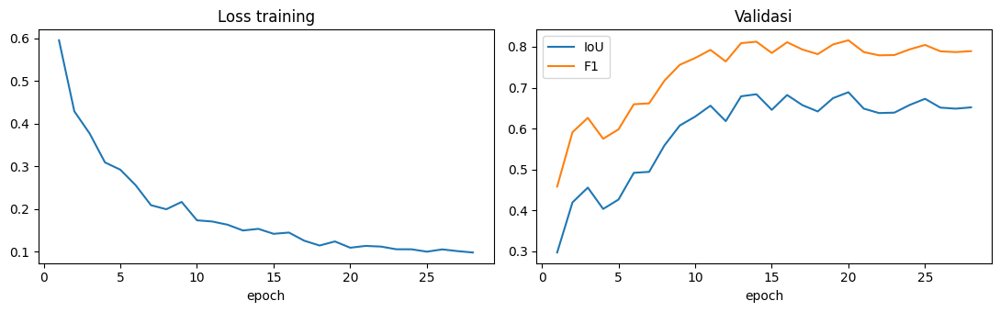

In [12]:
class BurnDataset(Dataset):
    def __init__(self, df, train=False):
        self.df = df.reset_index(drop=True)
        self.train = train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        six, valid = read_six(r.path_saat, r.sumber_label)
        with rasterio.open(r.path_mask) as s:
            mask = (s.read(1) > 0)
        if self.train:
            rng = np.random.default_rng(int(torch.randint(0, 2**31 - 1, (1,)).item()))
            six, valid, mask = augment(six, valid, mask, rng)
        dino, spec = preprocess(six, valid, MEAN, STD)
        return (torch.from_numpy(dino), torch.from_numpy(spec),
                torch.from_numpy(mask.astype(np.float32))[None], torch.from_numpy(valid.astype(np.float32))[None])


def masked_dice_bce(logits, y, v, smooth=1.0):
    bce = F.binary_cross_entropy_with_logits(logits, y, reduction="none")
    bce = (bce * v).sum() / v.sum().clamp(min=1)
    p = torch.sigmoid(logits) * v
    t = y * v
    dice = 1 - (2 * (p * t).sum() + smooth) / (p.sum() + t.sum() + smooth)
    return 0.5 * bce + 0.5 * dice


@torch.no_grad()
def evaluate(loader, thresholds=(0.5,)):
    model.eval()
    acc = {t: np.zeros(3) for t in thresholds}
    for dino, spec, y, v in loader:
        dino, spec, y, v = dino.to(DEVICE), spec.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            prob = torch.sigmoid(model(dino, spec).float())
        for t in thresholds:
            p = (prob > t).float() * v
            yy = y * v
            acc[t] += [(p * yy).sum().item(), (p * (1 - yy)).sum().item(), ((1 - p) * yy).sum().item()]
    out = {}
    for t, (tp, fp, fn) in acc.items():
        out[float(t)] = dict(iou=tp / max(tp + fp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1),
                             precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1))
    return out


tr_df, va_df, te_df = (tiles[tiles.split == s] for s in ("train", "val", "test"))
ds_tr = BurnDataset(tr_df, train=True)
weights = [CFG["POS_WEIGHT"] if f > 0 else 1.0 for f in tr_df.porsi_terbakar_label]
dl_tr = DataLoader(ds_tr, CFG["BATCH"], sampler=WeightedRandomSampler(weights, len(ds_tr), replacement=True),
                   num_workers=2, drop_last=True, pin_memory=AMP)
dl_va = DataLoader(BurnDataset(va_df), CFG["BATCH"], num_workers=2)
dl_te = DataLoader(BurnDataset(te_df), CFG["BATCH"], num_workers=2)
print(f"train {len(tr_df)} | val {len(va_df)} | test {len(te_df)}")

params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=CFG["LR"], weight_decay=1e-4)
steps = CFG["EPOCHS"] * max(1, len(dl_tr))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["LR"], total_steps=steps, pct_start=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=AMP)

MODEL_DIR = Path(CFG["OUT_DIR"]) / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
BEST = MODEL_DIR / "dinov3_burnseg_best.pt"
history, best_iou, best_ep = [], -1.0, 0
for ep in range(1, CFG["EPOCHS"] + 1):
    model.train(); t0 = time.time(); tot = 0.0
    for dino, spec, y, v in dl_tr:
        dino, spec, y, v = dino.to(DEVICE), spec.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = model(dino, spec)
        loss = masked_dice_bce(logits.float(), y, v)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item()
    m = evaluate(dl_va)[0.5]
    history.append(dict(epoch=ep, loss=tot / max(1, len(dl_tr)), **{f"val_{k}": v for k, v in m.items()}))
    print(f"ep {ep:2d} | loss {history[-1]['loss']:.4f} | val IoU {m['iou']:.4f} F1 {m['f1']:.4f} "
          f"P {m['precision']:.3f} R {m['recall']:.3f} | {time.time() - t0:.0f}s")
    if m["iou"] > best_iou:
        best_iou, best_ep = m["iou"], ep
        torch.save(model.trainable_state_dict(), BEST)
    elif ep - best_ep >= CFG["PATIENCE"]:
        print(f"early stopping (tidak membaik {CFG['PATIENCE']} epoch)")
        break

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.epoch, h.loss); ax[0].set_title("Loss training"); ax[0].set_xlabel("epoch")
ax[1].plot(h.epoch, h.val_iou, label="IoU"); ax[1].plot(h.epoch, h.val_f1, label="F1")
ax[1].set_title("Validasi"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(Path(CFG["OUT_DIR"]) / "kurva_training.png", dpi=120); plt.show()


## 6. Evaluasi di data uji


In [13]:
model.load_state_dict(torch.load(BEST, map_location=DEVICE), strict=False)
ths = tuple(np.round(np.arange(0.2, 0.81, 0.05), 2))
val_sweep = evaluate(dl_va, ths)
THR = max(val_sweep, key=lambda t: val_sweep[t]["iou"])
test_res = evaluate(dl_te, (0.5, THR))
metrics = dict(mode_data=MODE, backbone=model.backbone.name, best_epoch=best_ep, threshold=THR,
               val=val_sweep[THR], test_thr_0_5=test_res[0.5], test=test_res[THR],
               n_train=len(tr_df), n_val=len(va_df), n_test=len(te_df))
print(f"Ambang terbaik dari validasi: {THR}")
print(pd.DataFrame({"val (ambang terbaik)": val_sweep[THR], "test (ambang 0.5)": test_res[0.5],
                    "test (ambang terbaik)": test_res[THR]}).round(4))


@torch.no_grad()
def predict_prob(six, valid):
    dino, spec = preprocess(six, valid, MEAN, STD)
    with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
        logit = model(torch.from_numpy(dino)[None].to(DEVICE), torch.from_numpy(spec)[None].to(DEVICE))
    return torch.sigmoid(logit.float())[0, 0].cpu().numpy()


def load_ctx(path):
    if not isinstance(path, str) or not path or not os.path.exists(path):
        return None, None
    return read_six(path, "PC")


rows_out, VIS = [], {}
for r in te_df.itertuples():
    six, valid = read_six(r.path_saat, r.sumber_label)
    with rasterio.open(r.path_mask) as s:
        gt = s.read(1) > 0
    prob = predict_prob(six, valid)
    pred = (prob > THR) & valid
    pre, pre_v = load_ctx(getattr(r, "path_sebelum", ""))
    dur, dur_v = load_ctx(getattr(r, "path_saat_sr", ""))
    dnbr = dv = None
    if pre is not None and dur is not None:
        dnbr, dv = nbr(pre) - nbr(dur), pre_v & dur_v
    lv, used_d = severity_levels(pred, prob, dnbr, dv)
    area = pixel_area_ha(r.south, r.north, *gt.shape)
    tp, fp, fn = (pred & gt & valid).sum(), (pred & ~gt & valid).sum(), (~pred & gt & valid).sum()
    rows_out.append(dict(
        id=r.id, lat=r.lat, lon=r.lon, tanggal_kebakaran=r.tanggal_kebakaran,
        iou=tp / max(tp + fp + fn, 1),
        luas_label_ha=round(area[gt & valid].sum(), 1), luas_prediksi_ha=round(area[pred].sum(), 1),
        luas_tinggi_ha=round(area[lv == 3].sum(), 1), luas_sedang_ha=round(area[lv == 2].sum(), 1),
        luas_ringan_ha=round(area[lv == 1].sum(), 1),
        level_dari_dnbr_pct=round(100 * float(used_d[pred].mean()) if pred.any() else 0.0, 1)))
    VIS[r.id] = dict(six=six, valid=valid, gt=gt, prob=prob, lv=lv,
                     pre=(pre, pre_v), post=load_ctx(getattr(r, "path_sesudah", "")))

pred_df = pd.DataFrame(rows_out)
wx_cols = [c for c in tiles.columns if c in ("suhu_max_c", "rh_min_pct", "angin_max_kmh", "angin_dari",
                                             "hujan_30h_mm", "hari_tanpa_hujan")]
pred_df = pred_df.merge(tiles[["id", "path_sebelum", "path_saat", "path_sesudah"] + wx_cols], on="id", how="left")
pred_df.to_csv(Path(CFG["OUT_DIR"]) / "prediksi_test.csv", index=False)
print(pred_df[["id", "iou", "luas_label_ha", "luas_prediksi_ha", "luas_tinggi_ha", "luas_sedang_ha",
               "luas_ringan_ha", "level_dari_dnbr_pct"]].round(3).to_string(index=False))


Ambang terbaik dari validasi: 0.6
           val (ambang terbaik)  test (ambang 0.5)  test (ambang terbaik)
iou                      0.6892             0.8042                 0.8023
f1                       0.8160             0.8914                 0.8903
precision                0.7973             0.8932                 0.9027
recall                   0.8357             0.8897                 0.8783
                  id   iou  luas_label_ha  luas_prediksi_ha  luas_tinggi_ha  luas_sedang_ha  luas_ringan_ha  level_dari_dnbr_pct
L8_112063_200819_001 0.502          192.6             135.5            45.8            70.7            19.0                 80.7
L8_112063_210919_001 0.619         1405.4            1093.2           143.4           578.2           371.6                 99.8
L8_114061_190919_001 0.714         1222.7            1346.1           801.9           392.1           152.1                 99.9
L8_114062_190919_001 0.662          198.6             167.8            20.2     

### Visualisasi: sebelum · saat · sesudah · saat + mask prediksi
Tiga panel pertama adalah **citra asli tanpa olahan**: warna asli (Merah-Hijau-Biru) dengan skala reflektansi tetap
yang sama untuk semua panel (0 – `RAW_MAX`), tanpa stretch per citra, tanpa gamma, awan apa adanya.
Satu-satunya tambahan ada di panel terakhir: mask prediksi di atas citra saat kebakaran
(merah = tinggi, oranye = sedang, kuning = ringan).


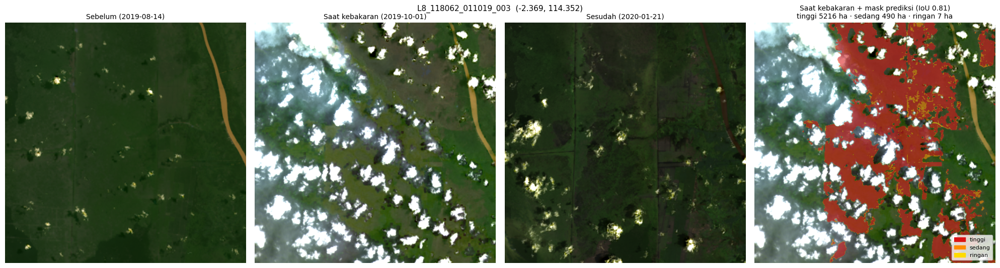

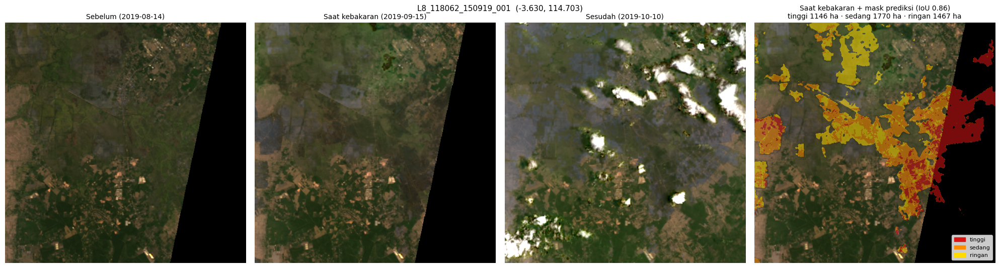

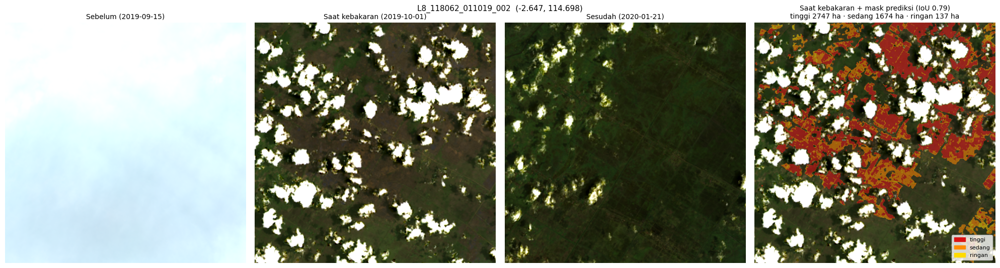

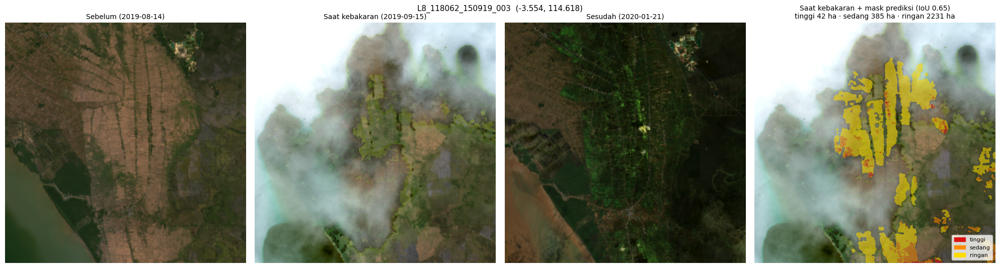

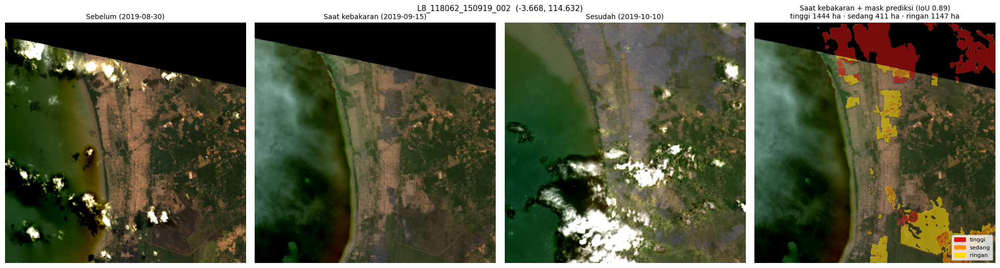

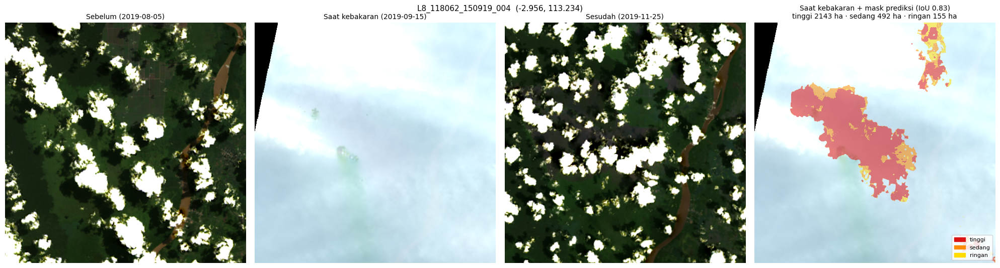

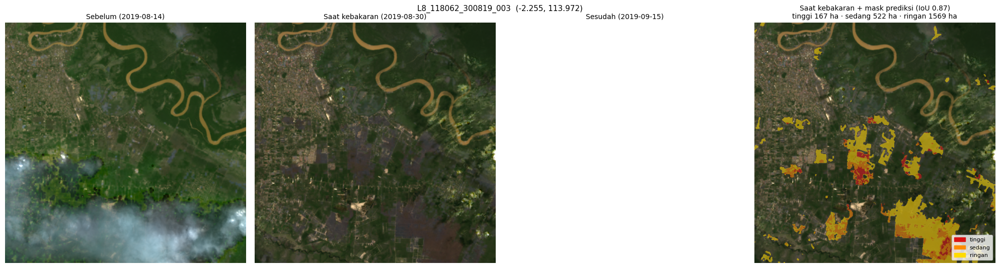

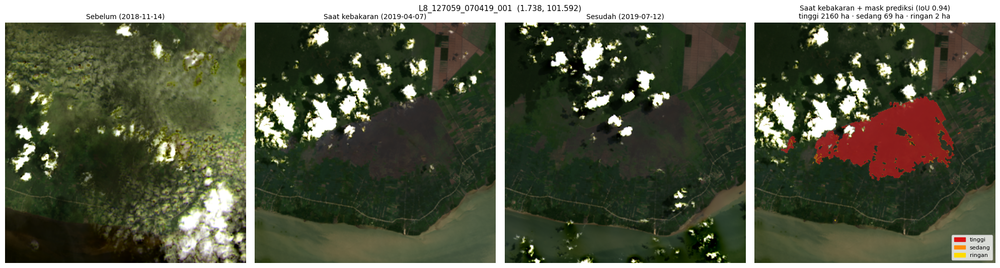

In [14]:
LEVEL_COLORS = {1: (1.0, 0.86, 0.0), 2: (1.0, 0.55, 0.0), 3: (0.86, 0.08, 0.08)}
RAW_MAX = 0.3   # reflektansi yang dipetakan ke putih; standar umum tampilan "natural color" Landsat
FIG_DIR = Path(CFG["OUT_DIR"]) / "gambar"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def raw_rgb(six):
    """Citra asli: band Merah, Hijau, Biru dengan satu skala linear tetap. Tidak ada pengeditan lain."""
    rgb = np.stack([six[2], six[1], six[0]], -1).astype(np.float32)
    data = ~np.all(six == 0, axis=0)
    if data.any() and np.nanmax(rgb[data]) > 2:   # data integer (BRIN uint16) → satu faktor linear untuk semua kanal
        rgb = rgb / np.percentile(rgb[data], 99.9) * RAW_MAX
    img = np.clip(rgb / RAW_MAX, 0, 1)
    img[~data] = 0
    return img


def load_sr(path):
    if not isinstance(path, str) or not path or not os.path.exists(path):
        return None
    return read_six(path, "PC")[0]


def overlay(base, lv, alpha=0.55):
    out = base.copy()
    for k, col in LEVEL_COLORS.items():
        m = lv == k
        out[m] = (1 - alpha) * out[m] + alpha * np.array(col)
    return out


def panel(ax, six, title):
    if six is None:
        ax.text(0.5, 0.5, "tidak tersedia", ha="center", va="center", transform=ax.transAxes)
        ax.set_facecolor("#eee"); ax.set_xticks([]); ax.set_yticks([])
    else:
        ax.imshow(raw_rgb(six)); ax.axis("off")
    ax.set_title(title, fontsize=10)


def fmt_date(x):
    return x if isinstance(x, str) and x else "-"


has_ctx = pred_df.path_sebelum.fillna("").astype(str).map(lambda p: bool(p) and os.path.exists(p))
order = (pred_df.assign(_ctx=has_ctx).sort_values(["_ctx", "luas_label_ha"], ascending=[False, False]).id.tolist())
pick = order[:CFG["VIS_SAMPLES"]]
tix, pix = tiles.set_index("id"), pred_df.set_index("id")
for tid in pick:
    d, r, p = VIS[tid], tix.loc[tid], pix.loc[tid]
    # citra saat: pakai versi surface reflectance (produk sama dengan sebelum/sesudah) bila ada
    saat = load_sr(r.get("path_saat_sr"))
    saat = saat if saat is not None else d["six"]
    fig, axs = plt.subplots(1, 4, figsize=(20, 5.4))
    panel(axs[0], d["pre"][0], f"Sebelum ({fmt_date(r.get('tgl_sebelum'))})")
    panel(axs[1], saat, f"Saat kebakaran ({r.tanggal_kebakaran})")
    panel(axs[2], d["post"][0], f"Sesudah ({fmt_date(r.get('tgl_sesudah'))})")
    axs[3].imshow(overlay(raw_rgb(saat), d["lv"])); axs[3].axis("off")
    axs[3].set_title(f"Saat kebakaran + mask prediksi (IoU {p.iou:.2f})\n"
                     f"tinggi {p.luas_tinggi_ha:.0f} ha · sedang {p.luas_sedang_ha:.0f} ha · ringan {p.luas_ringan_ha:.0f} ha",
                     fontsize=10)
    axs[3].legend(handles=[Patch(color=LEVEL_COLORS[3], label="tinggi"), Patch(color=LEVEL_COLORS[2], label="sedang"),
                           Patch(color=LEVEL_COLORS[1], label="ringan")], loc="lower right", fontsize=8, framealpha=0.8)
    fig.suptitle(f"{tid}  ({r.lat:.3f}, {r.lon:.3f})", fontsize=11)
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{tid}.png", dpi=150); plt.show()


## 7. Simpan model & semua output


In [15]:
FINAL = MODEL_DIR / "dinov3_burnseg.pt"


def to_py(o):
    """Ubah angka numpy → tipe Python biasa agar checkpoint bisa dimuat dengan torch.load(weights_only=True)."""
    if isinstance(o, dict):
        return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    return o


metrics = to_py(metrics)
torch.save(dict(
    state_dict=torch.load(BEST, map_location="cpu"),
    config=to_py(dict(backbone=model.backbone.name, img_size=CFG["IMG_SIZE"], mean=MEAN, std=STD,
                      bands=["blue", "green", "red", "nir", "swir1", "swir2"], n_spec=N_SPEC,
                      threshold=float(THR), sev_dnbr=CFG["SEV_DNBR"], sev_prob=CFG["SEV_PROB"])),
    metrics=metrics), FINAL)
json.dump(to_py(dict(metrics=metrics, history=history, cfg=CFG)),
          open(Path(CFG["OUT_DIR"]) / "metrics.json", "w"), indent=1, default=str)

# verifikasi: muat ulang dari file dan prediksi satu tile uji
reloaded = BurnSegDinoV3([model.backbone.name], CFG["IMG_SIZE"]).to(DEVICE)
ck = torch.load(FINAL, map_location=DEVICE, weights_only=True)
missing, unexpected = reloaded.load_state_dict(ck["state_dict"], strict=False)
assert not [k for k in missing if not k.startswith("backbone.m.")] and not unexpected, "checkpoint tidak cocok"
reloaded.eval()
r0 = te_df.iloc[0]
six, valid = read_six(r0.path_saat, r0.sumber_label)
dino, spec = preprocess(six, valid, ck["config"]["mean"], ck["config"]["std"])
with torch.no_grad(), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
    pr = torch.sigmoid(reloaded(torch.from_numpy(dino)[None].to(DEVICE), torch.from_numpy(spec)[None].to(DEVICE)).float())
print("model dimuat ulang OK — piksel terbakar terprediksi:", int((pr > ck["config"]["threshold"]).sum()))

import shutil
shutil_zip = Path(BASE) / "output_karhutla"
shutil.make_archive(str(shutil_zip), "zip", CFG["OUT_DIR"])
print("\nOutput:")
for p in sorted(Path(CFG["OUT_DIR"]).rglob("*")):
    if p.is_file() and p.suffix in (".pt", ".csv", ".json", ".png") and "gambar" not in str(p.parent):
        print(f"  {p}  ({p.stat().st_size / 1e6:.1f} MB)")
print(f"  {FIG_DIR}/  ({len(list(FIG_DIR.glob('*.png')))} gambar)")
print(f"  {shutil_zip}.zip  ← unduh semua sekaligus dari panel Output")
print("\nRingkasan test:", {k: round(v, 4) for k, v in metrics["test"].items()}, "| ambang", THR, "| data", MODE)


Backbone: vit_large_patch16_dinov3.sat493m {'img_size': 512}
  blok=24, dim=1024, lapisan dipakai=[5, 11, 17, 23], mean=(0.43, 0.411, 0.296), std=(0.213, 0.156, 0.143)
model dimuat ulang OK — piksel terbakar terprediksi: 4303

Output:
  /kaggle/working/output/dataset_karhutla.csv  (0.2 MB)
  /kaggle/working/output/kurva_training.png  (0.0 MB)
  /kaggle/working/output/metrics.json  (0.0 MB)
  /kaggle/working/output/model/dinov3_burnseg.pt  (27.8 MB)
  /kaggle/working/output/model/dinov3_burnseg_best.pt  (27.8 MB)
  /kaggle/working/output/prediksi_test.csv  (0.0 MB)
  /kaggle/working/output/gambar/  (8 gambar)
  /kaggle/working/output_karhutla.zip  ← unduh semua sekaligus dari panel Output

Ringkasan test: {'iou': 0.8023, 'f1': 0.8903, 'precision': 0.9027, 'recall': 0.8783} | ambang 0.6 | data brin


## 8. Bangun `model.mar` (TorchServe) + backbone DINOv3 di dalamnya
Isi arsip: bobot head hasil training, **backbone DINOv3 yang sama persis dengan yang dipakai training** (diambil langsung dari model di memori), kode model, handler, dan konfigurasi (ambang terbaik dari validasi). Server yang memakai `.mar` ini tidak perlu internet / Hugging Face.


In [16]:
MAR_SRC = Path(BASE) / "mar_src"
MAR_OUT = Path(BASE) / "mar_out"
shutil.rmtree(MAR_SRC, ignore_errors=True); shutil.rmtree(MAR_OUT, ignore_errors=True)
MAR_SRC.mkdir(parents=True); MAR_OUT.mkdir(parents=True)
MAR_SRC_STR = str(MAR_SRC)
print("folder sumber .mar:", MAR_SRC_STR)


folder sumber .mar: /kaggle/working/mar_src


In [17]:
%%writefile {MAR_SRC_STR}/burnseg_model.py
"""Model segmentasi area terbakar (DINOv3 beku + cabang spektral + decoder U-Net) dan preprocessing-nya.

Disalin PERSIS dari notebook training (karhutla_dinov3_kaggle.ipynb) supaya bobot bisa dimuat
tanpa perubahan. Jangan ubah nama atribut/lapisan — nama kunci state_dict bergantung padanya.

Input model: citra 6 band reflektansi, urutan [blue, green, red, nir, swir1, swir2].
"""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

N_SPEC = 6 + 5
BAND_NAMES = ["blue", "green", "red", "nir", "swir1", "swir2"]


# ---------------------------------------------------------------- preprocessing (numpy)
def nd(a, b):
    with np.errstate(divide="ignore", invalid="ignore"):
        r = (a - b) / (a + b)
    return np.nan_to_num(r, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)


def nbr(six):
    return nd(six[3], six[5])


def stretch(band, valid, lo=2, hi=98):
    v = band[valid]
    if v.size < 16:
        return np.zeros_like(band, dtype=np.float32)
    a, b = np.percentile(v, [lo, hi])
    if b - a < 1e-12:
        return np.zeros_like(band, dtype=np.float32)
    return np.clip((band - a) / (b - a), 0, 1).astype(np.float32)


def preprocess(six, valid, mean, std):
    """six: [6,H,W] float32. Return dino [3,H,W] (RGB ternormalisasi), spec [11,H,W]."""
    rgb = np.stack([stretch(six[i], valid) for i in (2, 1, 0)])
    dino = (rgb - np.asarray(mean, np.float32)[:, None, None]) / np.asarray(std, np.float32)[:, None, None]
    bands = np.stack([stretch(six[i], valid) for i in range(6)]) * 2 - 1
    blue, green, red, nir, sw1, sw2 = six
    idx = np.stack([nd(nir, sw2), nd(sw1, sw2), nd(nir, red), nd(green, nir), nd(sw2, sw1)])
    spec = np.concatenate([bands, idx]).astype(np.float32)
    dino[:, ~valid] = 0
    spec[:, ~valid] = 0
    return dino.astype(np.float32), spec


def severity_levels(pred, prob, sev_prob=(0.6, 0.8), sev_dnbr=(0.27, 0.44), dnbr=None, dnbr_valid=None):
    """0 = tidak terbakar, 1 = ringan, 2 = sedang, 3 = tinggi."""
    lv_prob = 1 + (prob >= sev_prob[0]).astype(np.uint8) + (prob >= sev_prob[1]).astype(np.uint8)
    if dnbr is not None:
        lv_d = 1 + (dnbr >= sev_dnbr[0]).astype(np.uint8) + (dnbr >= sev_dnbr[1]).astype(np.uint8)
        use_d = dnbr_valid.astype(bool)
        lv = np.where(use_d, lv_d, lv_prob)
    else:
        use_d = np.zeros(pred.shape, bool)
        lv = lv_prob
    return np.where(pred, lv, 0).astype(np.uint8), use_d


# ---------------------------------------------------------------- model (torch)
class DinoV3Backbone(nn.Module):
    def __init__(self, name, img_size=512, local_weights=None):
        super().__init__()
        import timm
        self.name = name
        kw_list = (dict(img_size=img_size), dict(dynamic_img_size=True), {})
        err = None
        for kw in kw_list:
            try:
                self.m = timm.create_model(name, pretrained=local_weights is None, num_classes=0, **kw)
                break
            except Exception as e:  # noqa: BLE001
                err = e
        else:
            raise RuntimeError(f"Gagal membuat backbone {name}: {err}")
        if local_weights is not None:
            sd = torch.load(local_weights, map_location="cpu", weights_only=True)
            self.m.load_state_dict(sd, strict=True)
        for p in self.m.parameters():
            p.requires_grad = False
        self.m.eval()
        n = len(self.m.blocks)
        self.indices = [n // 4 - 1, n // 2 - 1, 3 * n // 4 - 1, n - 1]
        self.dim = self.m.embed_dim if hasattr(self.m, "embed_dim") else self.m.num_features
        dc = timm.data.resolve_model_data_config(self.m)
        self.mean, self.std = tuple(dc["mean"]), tuple(dc["std"])
        self.norms = nn.ModuleList([nn.GroupNorm(1, self.dim) for _ in self.indices])

    def train(self, mode=True):
        super().train(mode)
        self.m.eval()
        return self

    @torch.no_grad()
    def _features(self, x):
        try:
            feats = self.m.forward_intermediates(x, indices=self.indices, output_fmt="NCHW", intermediates_only=True)
        except TypeError:
            _, feats = self.m.forward_intermediates(x, indices=self.indices, output_fmt="NCHW")
        return list(feats)

    def forward(self, x):
        return [norm(f.float()) for norm, f in zip(self.norms, self._features(x))]


def conv_gn(cin, cout, k=3, s=1):
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, k // 2, bias=False), nn.GroupNorm(8, cout), nn.GELU())


class SpectralEncoder(nn.Module):
    def __init__(self, cin=N_SPEC, chs=(32, 64, 128, 192, 256)):
        super().__init__()
        self.chs = chs
        self.stem = nn.Sequential(conv_gn(cin, chs[0]), conv_gn(chs[0], chs[0]))
        self.downs = nn.ModuleList([nn.Sequential(conv_gn(chs[i], chs[i + 1], s=2), conv_gn(chs[i + 1], chs[i + 1]))
                                    for i in range(len(chs) - 1)])

    def forward(self, x):
        f = [self.stem(x)]
        for d in self.downs:
            f.append(d(f[-1]))
        return f


class Up(nn.Module):
    def __init__(self, cin, cskip, cout, cextra=0):
        super().__init__()
        self.block = nn.Sequential(conv_gn(cin + cskip + cextra, cout), conv_gn(cout, cout))

    def forward(self, x, skip, extra=None):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.block(torch.cat([x, skip] + ([extra] if extra is not None else []), 1))


class BurnSegDinoV3(nn.Module):
    def __init__(self, backbone_name, img_size=512, fuse_dim=256, local_backbone=None):
        super().__init__()
        self.backbone = DinoV3Backbone(backbone_name, img_size, local_backbone)
        D = self.backbone.dim
        self.fuse = nn.Sequential(nn.Conv2d(D * 4, fuse_dim, 1, bias=False), nn.GroupNorm(8, fuse_dim), nn.GELU(),
                                  conv_gn(fuse_dim, fuse_dim))
        self.spec = SpectralEncoder()
        c = self.spec.chs
        self.dec16 = conv_gn(fuse_dim + c[4], c[4])
        self.up8 = Up(c[4], c[3], c[3], cextra=fuse_dim)
        self.up4 = Up(c[3], c[2], c[2])
        self.up2 = Up(c[2], c[1], c[1])
        self.up1 = Up(c[1], c[0], c[0])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, dino, spec):
        f = self.fuse(torch.cat(self.backbone(dino), 1))
        s = self.spec(spec)
        f16 = F.interpolate(f, size=s[4].shape[-2:], mode="bilinear", align_corners=False)
        f8 = F.interpolate(f, size=s[3].shape[-2:], mode="bilinear", align_corners=False)
        x = self.dec16(torch.cat([f16, s[4]], 1))
        x = self.up8(x, s[3], f8)
        x = self.up4(x, s[2])
        x = self.up2(x, s[1])
        x = self.up1(x, s[0])
        return self.head(x)


def load_head_weights(model, path):
    """Muat bobot head (checkpoint tanpa backbone). Error jika ada kunci di luar backbone yang hilang/tak dikenal."""
    sd = torch.load(path, map_location="cpu", weights_only=True)
    if isinstance(sd, dict) and "state_dict" in sd:   # format dinov3_burnseg.pt (final) juga diterima
        sd = sd["state_dict"]
    exp_dim = model.backbone.dim * 4
    got_dim = sd["fuse.0.weight"].shape[1]
    if got_dim != exp_dim:
        raise RuntimeError(f"Backbone tidak cocok: checkpoint butuh dim {got_dim // 4}, backbone {model.backbone.name} "
                           f"punya dim {model.backbone.dim}. Ubah 'backbone' di setup_config.json.")
    missing, unexpected = model.load_state_dict(sd, strict=False)
    missing = [k for k in missing if not k.startswith("backbone.m.")]
    if missing or unexpected:
        raise RuntimeError(f"Checkpoint tidak cocok. missing={missing[:5]} unexpected={unexpected[:5]}")
    return model


Writing /kaggle/working/mar_src/burnseg_model.py


In [18]:
%%writefile {MAR_SRC_STR}/karhutla_handler.py
"""Handler TorchServe untuk segmentasi area terbakar (DINOv3 + cabang spektral).

Tidak bergantung pada paket `ts`, jadi bisa dites langsung di Python biasa:
    from karhutla_handler import KarhutlaHandler, SimpleContext
    h = KarhutlaHandler(); h.initialize(SimpleContext("folder_berisi_isi_mar"))
    out = h.handle([{"saat": open("tile.tif", "rb").read()}], None)

Input per request (multipart form atau JSON):
    saat     : GeoTIFF / .npy citra saat kebakaran (WAJIB). Alias: data, body, file, image.
               Boleh berupa bytes, base64, {"b64": "..."} (Vertex AI), atau path gs:// / https://
               (field saat_uri / sebelum_uri juga diterima).
    sebelum  : GeoTIFF / .npy citra sebelum kebakaran, grid sama (opsional → level dari dNBR).
    threshold, band_order ("auto" | "six" | "brin" | "landsat7"), pixel_size_m, return_overlay (true/false)
    Pada JSON, file dikirim sebagai string base64.

Format citra yang diterima (model butuh band NIR & SWIR, jadi foto RGB biasa TIDAK bisa):
    6 band  : blue, green, red, nir, swir1, swir2                    (band_order=six)
    7 band  : 6 band di atas + band ke-7 mask cerah 0/1 (keluaran notebook) — terdeteksi otomatis
              atau Landsat SR_B1..SR_B7                               (band_order=landsat7)
    8 band  : format dataset BRIN: B1..B7 + cirrus                    (band_order=brin)
"""
import base64
import io
import json
import logging
import os

import numpy as np
import torch

from burnseg_model import BurnSegDinoV3, load_head_weights, nbr, preprocess, severity_levels

log = logging.getLogger(__name__)

DEFAULT_CFG = {
    "backbone": "vit_large_patch16_dinov3.sat493m",
    "img_size": 512,
    "threshold": 0.5,
    "sev_prob": [0.6, 0.8],
    "sev_dnbr": [0.27, 0.44],
    "overlap": 0.25,
    "batch_tiles": 4,
    "local_backbone": None,
    "default_pixel_size_m": 30.0,
}
LEVEL_COLORS = {1: (255, 219, 0), 2: (255, 140, 0), 3: (219, 20, 20)}


class SimpleContext:
    """Pengganti context TorchServe untuk tes lokal."""

    def __init__(self, model_dir, serialized_file="dinov3_burnseg_best.pt", gpu_id=0):
        self.system_properties = {"model_dir": model_dir, "gpu_id": gpu_id}
        self.manifest = {"model": {"serializedFile": serialized_file}}


# ---------------------------------------------------------------- pembacaan input
def _load_uri(uri):
    """Baca file dari gs://bucket/path (Vertex/GCP) atau http(s)://."""
    if uri.startswith("gs://"):
        from google.cloud import storage
        bucket, _, name = uri[5:].partition("/")
        return storage.Client().bucket(bucket).blob(name).download_as_bytes()
    if uri.startswith(("http://", "https://")):
        import urllib.request
        with urllib.request.urlopen(uri, timeout=120) as r:
            return r.read()
    raise ValueError(f"URI tidak didukung: {uri[:40]} (pakai gs:// atau https://)")


def _as_bytes(v):
    if v is None:
        return None
    if isinstance(v, (bytes, bytearray)):
        return bytes(v)
    if isinstance(v, dict) and "b64" in v:          # konvensi Vertex AI: {"b64": "..."}
        return base64.b64decode(v["b64"])
    if isinstance(v, str):
        if v.startswith(("gs://", "http://", "https://")):
            return _load_uri(v)
        return base64.b64decode(v)
    raise ValueError(f"Tipe input tidak dikenali: {type(v).__name__}")


def _field(row, *names):
    for n in names:
        if n in row and row[n] is not None:
            v = row[n]
            return v.decode() if isinstance(v, (bytes, bytearray)) and n not in ("saat", "sebelum", "data", "body",
                                                                                 "file", "image", "saat_uri",
                                                                                 "sebelum_uri") else v
    return None


def read_raster(blob):
    """Return (arr [C,H,W] float32, georef dict atau None)."""
    head = blob[:8]
    if head.startswith(b"\x93NUMPY"):
        arr = np.load(io.BytesIO(blob), allow_pickle=False)
        if arr.ndim == 2:
            arr = arr[None]
        return arr.astype(np.float32), None
    if head[:4] in (b"II*\x00", b"MM\x00*", b"II+\x00", b"MM\x00+"):
        from rasterio.io import MemoryFile
        with MemoryFile(blob) as mf, mf.open() as src:
            arr = src.read().astype(np.float32)
            geo = {"transform": tuple(src.transform)[:6], "crs": src.crs.to_string() if src.crs else None,
                   "geographic": bool(src.crs and src.crs.is_geographic), "bounds": tuple(src.bounds)}
        return arr, geo
    if head.startswith(b"\x89PNG") or head[:3] == b"\xff\xd8\xff":
        raise ValueError("Foto PNG/JPEG hanya punya 3 kanal (RGB). Model ini butuh 6 band reflektansi "
                         "(blue, green, red, NIR, SWIR1, SWIR2) dari Landsat/Sentinel-2. Kirim GeoTIFF multiband atau .npy.")
    raise ValueError("Format tidak dikenali. Kirim GeoTIFF multiband atau .npy [C,H,W].")


def to_six(arr, band_order="auto"):
    """Return (six [6,H,W], valid [H,W], keterangan)."""
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
    c = arr.shape[0]
    if band_order == "auto":
        if c == 6:
            band_order = "six"
        elif c == 8:
            band_order = "brin"
        elif c == 7:
            last = arr[6]
            band_order = "six+clear" if np.isin(np.unique(last[:: max(1, last.shape[0] // 64)]), [0, 1]).all() \
                else "landsat7"
        else:
            raise ValueError(f"Jumlah band {c} tidak didukung (butuh 6, 7, atau 8). Set band_order secara eksplisit.")
    if band_order == "six":
        six = arr[:6]
        valid = ~np.all(six == 0, axis=0)
    elif band_order == "six+clear":
        six = arr[:6]
        valid = (arr[6] > 0.5) & ~np.all(six == 0, axis=0)
    elif band_order in ("brin", "landsat7"):
        if c < 7:
            raise ValueError(f"band_order={band_order} butuh minimal 7 band, dapat {c}")
        six = arr[1:7]
        valid = ~np.all(six == 0, axis=0)
    else:
        raise ValueError(f"band_order tidak dikenal: {band_order}")
    return np.ascontiguousarray(six, dtype=np.float32), valid, band_order


def pixel_area_ha(geo, shape, pixel_size_m):
    h, w = shape
    if geo and geo.get("transform"):
        a, b, c, d, e, f = geo["transform"]
        if geo.get("geographic"):
            lat = f + (np.arange(h) + 0.5) * e
            dx = abs(a) * 111320 * np.cos(np.radians(lat))
            dy = abs(e) * 110574
            return np.repeat((dx * dy / 1e4)[:, None], w, axis=1)
        return np.full((h, w), abs(a * e) / 1e4)
    return np.full((h, w), (pixel_size_m ** 2) / 1e4)


def png_b64(img):
    from PIL import Image
    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="PNG", optimize=True)
    return base64.b64encode(buf.getvalue()).decode()


def overlay_rgb(six, valid, levels, raw_max=0.3, alpha=0.55):
    """Citra warna asli (skala linear tetap) + mask 3 level."""
    rgb = np.stack([six[2], six[1], six[0]], -1).astype(np.float32)
    if valid.any() and np.nanmax(rgb[valid]) > 2:  # data integer (mis. BRIN uint16)
        rgb = rgb / np.percentile(rgb[valid], 99.9) * raw_max
    img = np.clip(rgb / raw_max, 0, 1)
    img[~valid] = 0
    for k, col in LEVEL_COLORS.items():
        m = levels == k
        img[m] = (1 - alpha) * img[m] + alpha * (np.array(col) / 255.0)
    return (img * 255).round().astype(np.uint8)


# ---------------------------------------------------------------- handler
class KarhutlaHandler:
    def __init__(self):
        self.initialized = False

    def initialize(self, context):
        props = context.system_properties
        model_dir = props.get("model_dir", ".")
        cfg = dict(DEFAULT_CFG)
        cfg_path = os.path.join(model_dir, "setup_config.json")
        if os.path.exists(cfg_path):
            cfg.update(json.load(open(cfg_path)))
        self.cfg = cfg
        gpu = props.get("gpu_id")
        self.device = torch.device(f"cuda:{gpu}" if torch.cuda.is_available() and gpu is not None else
                                   ("cuda" if torch.cuda.is_available() else "cpu"))
        local_bb = cfg.get("local_backbone")
        local_bb = os.path.join(model_dir, local_bb) if local_bb else None
        if local_bb and not os.path.exists(local_bb):
            raise FileNotFoundError(f"local_backbone {local_bb} tidak ada di arsip")
        serialized = context.manifest["model"]["serializedFile"]
        log.info("Memuat backbone %s (lokal=%s) di %s", cfg["backbone"], bool(local_bb), self.device)
        model = BurnSegDinoV3(cfg["backbone"], cfg["img_size"], local_backbone=local_bb)
        load_head_weights(model, os.path.join(model_dir, serialized))
        self.model = model.to(self.device).eval()
        self.mean, self.std = model.backbone.mean, model.backbone.std
        self.amp = self.device.type == "cuda"
        self.initialized = True
        log.info("Model siap. mean=%s std=%s", self.mean, self.std)

    # -- inferensi jendela geser (tile 512, sama dengan training)
    @torch.no_grad()
    def predict_prob(self, six, valid):
        tile = self.cfg["img_size"]
        H, W = valid.shape
        ph, pw = max(0, tile - H), max(0, tile - W)
        if ph or pw:
            six = np.pad(six, ((0, 0), (0, ph), (0, pw)))
            valid = np.pad(valid, ((0, ph), (0, pw)))
        Hp, Wp = valid.shape
        stride = max(16, int(tile * (1 - self.cfg["overlap"])))

        def starts(n):
            if n <= tile:
                return [0]
            s = list(range(0, n - tile + 1, stride))
            return s if s[-1] == n - tile else s + [n - tile]

        win = np.outer(np.hanning(tile), np.hanning(tile)).astype(np.float32) + 1e-3
        acc = np.zeros((Hp, Wp), np.float32)
        wsum = np.zeros_like(acc)
        jobs = [(r, c) for r in starts(Hp) for c in starts(Wp)]
        bs = self.cfg["batch_tiles"]
        for i in range(0, len(jobs), bs):
            batch = jobs[i:i + bs]
            ps = [preprocess(six[:, r:r + tile, c:c + tile], valid[r:r + tile, c:c + tile], self.mean, self.std)
                  for r, c in batch]
            dino = torch.from_numpy(np.stack([p[0] for p in ps])).to(self.device)
            spec = torch.from_numpy(np.stack([p[1] for p in ps])).to(self.device)
            with torch.autocast(self.device.type, dtype=torch.float16, enabled=self.amp):
                prob = torch.sigmoid(self.model(dino, spec).float())[:, 0].cpu().numpy()
            for (r, c), pr in zip(batch, prob):
                v = valid[r:r + tile, c:c + tile]
                acc[r:r + tile, c:c + tile] += pr * win * v
                wsum[r:r + tile, c:c + tile] += win * v
        prob = np.where(wsum > 0, acc / np.maximum(wsum, 1e-6), 0.0)
        return prob[:H, :W].astype(np.float32)

    def _one(self, row):
        if isinstance(row, (bytes, bytearray)):
            row = {"body": row}
        body = row.get("body") if isinstance(row.get("body"), dict) else None
        if body is None and isinstance(row.get("data"), dict):
            body = row["data"]
        src = body if body is not None else row
        saat_raw = _field(src, "saat", "saat_uri", "data", "body", "file", "image")
        if saat_raw is None:
            raise ValueError("Field 'saat' (citra saat kebakaran) wajib diisi.")
        thr = float(_field(src, "threshold") or self.cfg["threshold"])
        band_order = str(_field(src, "band_order") or "auto")
        px = float(_field(src, "pixel_size_m") or self.cfg["default_pixel_size_m"])
        want_overlay = str(_field(src, "return_overlay") or "true").lower() not in ("0", "false", "no")

        arr, geo = read_raster(_as_bytes(saat_raw))
        six, valid, used_order = to_six(arr, band_order)
        if valid.mean() < 0.05:
            raise ValueError("Hampir semua piksel kosong/tertutup (valid < 5%).")
        prob = self.predict_prob(six, valid)
        pred = (prob > thr) & valid

        notes, dnbr, dv = [], None, None
        pre_raw = _field(src, "sebelum", "sebelum_uri")
        if pre_raw is not None:
            parr, _ = read_raster(_as_bytes(pre_raw))
            psix, pvalid, _ = to_six(parr, band_order if band_order != "auto" else "auto")
            if psix.shape[1:] != six.shape[1:]:
                notes.append(f"Citra sebelum berukuran {psix.shape[1:]} ≠ citra saat {six.shape[1:]}; dNBR dilewati.")
            else:
                dnbr, dv = nbr(psix) - nbr(six), pvalid & valid
        levels, used_d = severity_levels(pred, prob, self.cfg["sev_prob"], self.cfg["sev_dnbr"], dnbr, dv)
        area = pixel_area_ha(geo, valid.shape, px)
        if geo is None:
            notes.append(f"Tanpa georeferensi: luas dihitung dengan asumsi piksel {px:g} m.")
        if dnbr is None:
            notes.append("Level keparahan dari probabilitas model (tidak ada citra sebelum). Kirim 'sebelum' untuk dNBR.")
        frac_d = float(used_d[pred].mean()) if pred.any() else 0.0
        out = {
            "status": "ok",
            "ukuran": list(valid.shape),
            "band_order": used_order,
            "threshold": thr,
            "sumber_level": "dNBR" if frac_d > 0.99 else ("probabilitas" if frac_d < 0.01 else "campuran"),
            "luas_ha": {
                "tinggi": round(float(area[levels == 3].sum()), 2),
                "sedang": round(float(area[levels == 2].sum()), 2),
                "ringan": round(float(area[levels == 1].sum()), 2),
                "total_terbakar": round(float(area[pred].sum()), 2),
                "teramati": round(float(area[valid].sum()), 2),
            },
            "porsi_terbakar_pct": round(100 * float(pred.sum() / max(valid.sum(), 1)), 2),
            "porsi_tidak_teramati_pct": round(100 * float(1 - valid.mean()), 2),
            "prob_max": round(float(prob[valid].max()), 4),
            "georef": geo,
            "mask_level_png": png_b64(levels),
            "catatan": notes,
        }
        if want_overlay:
            out["overlay_png"] = png_b64(overlay_rgb(six, valid, levels))
        return out

    def handle(self, data, context):
        if not self.initialized:
            self.initialize(context)
        results = []
        for row in data or []:
            try:
                results.append(self._one(row))
            except ValueError as e:  # input tidak valid → pesan jelas, tanpa traceback
                log.warning("Input ditolak: %s", e)
                results.append({"status": "error", "pesan": f"{type(e).__name__}: {e}"})
            except Exception as e:  # noqa: BLE001 — satu request gagal tidak menjatuhkan batch
                log.exception("Request gagal")
                results.append({"status": "error", "pesan": f"{type(e).__name__}: {e}"})
        return results


_service = KarhutlaHandler()


def handle(data, context):
    """Titik masuk TorchServe (handler berbasis fungsi)."""
    if data is None:  # TorchServe memanggil handle(None, ctx) saat model dimuat
        if not _service.initialized:
            _service.initialize(context)
        return None
    return _service.handle(data, context)


Writing /kaggle/working/mar_src/karhutla_handler.py


In [19]:
import datetime, zipfile, subprocess
MAR_NAME = "model"            # file model.mar (nama ini juga syarat Vertex AI)
BACKBONE_NAME = model.backbone.name

# 1) bobot head terbaik (tanpa backbone) — format sama dengan dinov3_burnseg_best.pt
head_sd = torch.load(BEST, map_location="cpu", weights_only=True)
torch.save(head_sd, MAR_SRC / "dinov3_burnseg_best.pt")
# 2) backbone: diambil dari model yang dipakai training (bukan unduhan ulang) → dijamin identik
bb_sd = {k: v.detach().cpu().contiguous() for k, v in model.backbone.m.state_dict().items()}
torch.save(bb_sd, MAR_SRC / "backbone.pt")
print(f"head {sum(v.numel() for v in head_sd.values())/1e6:.2f} jt param | backbone {BACKBONE_NAME} "
      f"{sum(v.numel() for v in bb_sd.values())/1e6:.0f} jt param ({(MAR_SRC/'backbone.pt').stat().st_size/1e9:.2f} GB)")
del bb_sd
# 3) konfigurasi handler — ambang dari validasi
setup_cfg = {"backbone": BACKBONE_NAME, "img_size": CFG["IMG_SIZE"], "threshold": float(THR),
             "sev_prob": list(CFG["SEV_PROB"]), "sev_dnbr": list(CFG["SEV_DNBR"]), "overlap": 0.25,
             "batch_tiles": 4, "local_backbone": "backbone.pt", "default_pixel_size_m": 30.0}
(MAR_SRC / "setup_config.json").write_text(json.dumps(setup_cfg, indent=2))
(MAR_SRC / "requirements.txt").write_text("timm>=1.0.20\nrasterio\npillow\nnumpy\ngoogle-cloud-storage\n")
print(json.dumps(setup_cfg, indent=1))

# 4) arsipkan
extra = ",".join(str(MAR_SRC / f) for f in ["burnseg_model.py", "setup_config.json", "backbone.pt"])
cmd = ["torch-model-archiver", "--model-name", MAR_NAME, "--version", "1.0",
       "--serialized-file", str(MAR_SRC / "dinov3_burnseg_best.pt"), "--handler", str(MAR_SRC / "karhutla_handler.py"),
       "--extra-files", extra, "--requirements-file", str(MAR_SRC / "requirements.txt"),
       "--export-path", str(MAR_OUT), "--force"]
r = subprocess.run(cmd, capture_output=True, text=True)
MAR = MAR_OUT / f"{MAR_NAME}.mar"
if r.returncode != 0 or not MAR.exists():
    print("torch-model-archiver gagal → arsip dibuat manual.\n", r.stderr[-800:])
    manifest = {"createdOn": datetime.datetime.now().strftime("%d/%m/%Y %H:%M:%S"), "runtime": "python",
                "model": {"modelName": MAR_NAME, "serializedFile": "dinov3_burnseg_best.pt",
                          "handler": "karhutla_handler.py", "modelVersion": "1.0", "requirementsFile": "requirements.txt"},
                "archiverVersion": "manual"}
    with zipfile.ZipFile(MAR, "w", zipfile.ZIP_STORED, allowZip64=True) as z:
        for f in ["dinov3_burnseg_best.pt", "karhutla_handler.py", "burnseg_model.py", "setup_config.json",
                  "backbone.pt", "requirements.txt"]:
            z.write(MAR_SRC / f, f)
        z.writestr("MAR-INF/MANIFEST.json", json.dumps(manifest, indent=2))
with zipfile.ZipFile(MAR) as z:
    names = set(z.namelist()); man = json.loads(z.read("MAR-INF/MANIFEST.json"))
need = {"dinov3_burnseg_best.pt", "karhutla_handler.py", "burnseg_model.py", "setup_config.json", "backbone.pt"}
assert need <= names, f"file hilang di .mar: {need - names}"
print(f"\n{MAR}  {MAR.stat().st_size/1e9:.2f} GB\nmanifest: {man['model']}")


head 6.95 jt param | backbone vit_large_patch16_dinov3.sat493m 303 jt param (1.21 GB)
{
 "backbone": "vit_large_patch16_dinov3.sat493m",
 "img_size": 512,
 "threshold": 0.6,
 "sev_prob": [
  0.6,
  0.8
 ],
 "sev_dnbr": [
  0.27,
  0.44
 ],
 "overlap": 0.25,
 "batch_tiles": 4,
 "local_backbone": "backbone.pt",
 "default_pixel_size_m": 30.0
}

/kaggle/working/mar_out/model.mar  1.15 GB
manifest: {'modelName': 'model', 'serializedFile': 'dinov3_burnseg_best.pt', 'handler': 'karhutla_handler.py', 'modelVersion': '1.0', 'requirementsFile': 'requirements.txt'}


## 9. Uji `model.mar` secara offline
Arsip diekstrak dan dijalankan di **proses terpisah dengan Hugging Face dimatikan** (`HF_HUB_OFFLINE=1`, cache kosong) — kalau lolos, backbone benar-benar dimuat dari dalam `.mar`.
Citra uji = tile uji dengan area terbakar terbesar (citra saat + sebelum dari langkah 1). Hasil luas dari `.mar` dibandingkan dengan prediksi notebook untuk tile yang sama → harus hampir identik.


In [20]:
for _n in ("reloaded", "pr"):
    globals().pop(_n, None)
import gc; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None
_ctx = pred_df.path_sebelum.fillna("").astype(str).map(lambda p: bool(p) and os.path.exists(p))
uji = pred_df.assign(_ctx=_ctx).sort_values(["_ctx", "luas_label_ha"], ascending=[False, False]).iloc[0]
uji_row = tiles.set_index("id").loc[uji.id]
UJI_DIR = Path(BASE) / "uji_mar"; shutil.rmtree(UJI_DIR, ignore_errors=True); UJI_DIR.mkdir()
saat_path = uji_row.path_saat
pre_path = uji_row.path_sebelum if isinstance(uji_row.path_sebelum, str) and os.path.exists(uji_row.path_sebelum) else ""
print("tile uji:", uji.id, "| saat:", saat_path, "| sebelum:", pre_path or "(tidak ada)")

(UJI_DIR / "run_test.py").write_text('''
import json, sys, time, zipfile, base64
from pathlib import Path
mar, saat, pre, out = Path(sys.argv[1]), Path(sys.argv[2]), sys.argv[3], Path(sys.argv[4])
ext = out / "ext"; zipfile.ZipFile(mar).extractall(ext); sys.path.insert(0, str(ext))
import karhutla_handler as KH
man = json.loads((ext / "MAR-INF" / "MANIFEST.json").read_text())
h = KH.KarhutlaHandler(); t = time.time()
h.initialize(KH.SimpleContext(str(ext), man["model"]["serializedFile"]))
t_init = time.time() - t
req = {"saat": saat.read_bytes()}
if pre:
    req["sebelum"] = Path(pre).read_bytes()
t = time.time()
res = h.handle([req, {"saat": saat.read_bytes(), "return_overlay": "false"}, {"saat": b"\\x89PNG\\r\\n\\x1a\\n0000"}], None)
if res[0].get("status") == "ok":
    (out / "overlay.png").write_bytes(base64.b64decode(res[0]["overlay_png"]))
slim = [{k: v for k, v in r.items() if not k.endswith("_png") and k != "georef"} for r in res]
json.dump({"init_s": t_init, "infer_s": time.time() - t, "device": str(h.device), "hasil": slim},
          open(out / "hasil.json", "w"), indent=1)
''')
env = dict(os.environ, HF_HUB_OFFLINE="1", TRANSFORMERS_OFFLINE="1", HF_HOME=str(UJI_DIR / "hf_kosong"))
r = subprocess.run([sys.executable, str(UJI_DIR / "run_test.py"), str(MAR), saat_path, pre_path, str(UJI_DIR)],
                   capture_output=True, text=True, env=env)
print(r.stdout[-1500:]); print(r.stderr[-3000:])
assert r.returncode == 0, "Uji offline GAGAL — lihat error di atas."
hasil = json.load(open(UJI_DIR / "hasil.json"))
print(f"initialize {hasil['init_s']:.1f}s | inferensi 3 request {hasil['infer_s']:.1f}s | {hasil['device']}")
for i, x in enumerate(hasil["hasil"]):
    print(i, x)
assert hasil["hasil"][0]["status"] == "ok" and hasil["hasil"][1]["status"] == "ok", "request valid gagal"
assert hasil["hasil"][2]["status"] == "error", "foto PNG seharusnya ditolak"

luas_mar = hasil["hasil"][1]["luas_ha"]["total_terbakar"]
luas_nb = float(uji.luas_prediksi_ha)
selisih = abs(luas_mar - luas_nb) / max(luas_nb, 1.0)
print(f"\nluas terbakar — .mar: {luas_mar:.1f} ha | notebook: {luas_nb:.1f} ha | selisih {selisih:.2%}")
assert selisih < 0.03, "Hasil .mar berbeda dari notebook (>3%) — cek preprocessing/ambang."
print("✅ UJI OFFLINE LOLOS — model.mar memuat backbone dari arsipnya sendiri dan hasilnya sama dengan notebook.")


tile uji: L8_118062_011019_003 | saat: /kaggle/working/data/brin/images/L8_118062_011019_003.tif | sebelum: /kaggle/working/data/context/L8_118062_011019_003_sebelum.tif

Input ditolak: Foto PNG/JPEG hanya punya 3 kanal (RGB). Model ini butuh 6 band reflektansi (blue, green, red, NIR, SWIR1, SWIR2) dari Landsat/Sentinel-2. Kirim GeoTIFF multiband atau .npy.

initialize 8.4s | inferensi 3 request 1.9s | cuda:0
0 {'status': 'ok', 'ukuran': [512, 512], 'band_order': 'brin', 'threshold': 0.6, 'sumber_level': 'dNBR', 'luas_ha': {'tinggi': 3562.62, 'sedang': 2095.06, 'ringan': 55.5, 'total_terbakar': 5713.18, 'teramati': 20149.99}, 'porsi_terbakar_pct': 28.35, 'porsi_tidak_teramati_pct': 0.0, 'prob_max': 0.9978, 'catatan': []}
1 {'status': 'ok', 'ukuran': [512, 512], 'band_order': 'brin', 'threshold': 0.6, 'sumber_level': 'probabilitas', 'luas_ha': {'tinggi': 5420.25, 'sedang': 292.94, 'ringan': 0.0, 'total_terbakar': 5713.18, 'teramati': 20149.99}, 'porsi_terbakar_pct': 28.35, 'porsi_tidak_

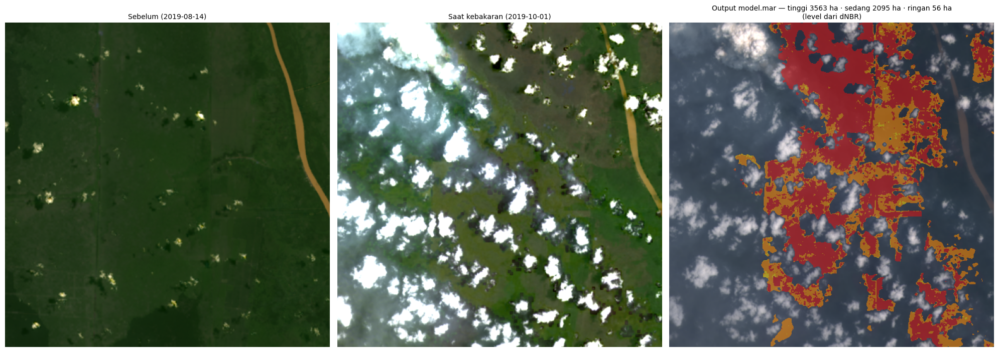

In [21]:
from PIL import Image
r0 = hasil["hasil"][0]; L = r0["luas_ha"]
pre_six = load_sr(pre_path) if pre_path else None
fig, ax = plt.subplots(1, 3, figsize=(20, 7))
panel(ax[0], pre_six, f"Sebelum ({fmt_date(uji_row.get('tgl_sebelum'))})")
saat_sr = load_sr(uji_row.get("path_saat_sr"))
panel(ax[1], saat_sr if saat_sr is not None else read_six(saat_path, uji_row.sumber_label)[0],
      f"Saat kebakaran ({uji_row.tanggal_kebakaran})")
ax[2].imshow(Image.open(UJI_DIR / "overlay.png")); ax[2].axis("off")
ax[2].set_title(f"Output model.mar — tinggi {L['tinggi']:.0f} ha · sedang {L['sedang']:.0f} ha · ringan {L['ringan']:.0f} ha"
                f"\n(level dari {r0['sumber_level']})", fontsize=10)
plt.tight_layout(); plt.savefig(Path(BASE) / "uji_model_mar.png", dpi=110); plt.show()


## 10. Link unduhan


In [22]:
from IPython.display import FileLink, HTML, display
final_mar = Path(BASE) / "model.mar"
shutil.move(str(MAR), final_mar)
for p in [MAR_SRC, MAR_OUT, UJI_DIR / "ext", UJI_DIR / "hf_kosong"]:
    shutil.rmtree(p, ignore_errors=True)
(Path(BASE) / "README_model_mar.txt").write_text(
    f"model.mar — backbone {BACKBONE_NAME} ada DI DALAM arsip (offline). Ambang default {float(THR):.2f} (dari validasi).\n"
    f"Test IoU {metrics['test']['iou']:.3f} | F1 {metrics['test']['f1']:.3f} | data {MODE}\n\n"
    "TorchServe (butuh Java 17):\n"
    "  pip install torchserve torch-model-archiver timm rasterio pillow\n"
    "  mkdir model_store && cp model.mar model_store/\n"
    "  torchserve --start --ncs --model-store model_store --models model.mar --disable-token-auth\n"
    "  curl -F saat=@saat.tif -F sebelum=@sebelum.tif http://127.0.0.1:8080/predictions/model\n\n"
    "Input: GeoTIFF/NPY 6 band (B,G,R,NIR,SWIR1,SWIR2), 7 band (+mask cerah 0/1), atau 8 band format BRIN.\n"
    "Foto RGB biasa (JPG/PNG) ditolak — model butuh NIR & SWIR.\n"
    "Muat bobot di Python lain: torch.load(path, weights_only=True).\n")
os.chdir(BASE)
print(f"model.mar: {final_mar.stat().st_size/1e9:.2f} GB")
display(HTML("<h3>Klik untuk mengunduh</h3>"))
for f in ["model.mar", "output_karhutla.zip", "uji_model_mar.png", "README_model_mar.txt"]:
    if (Path(BASE) / f).exists():
        display(FileLink(f))
print("\nKalau link tidak bisa diklik: panel kanan → Output (/kaggle/working) → model.mar → ⋮ → Download.\n"
      "Untuk menyimpan permanen: Save Version → Save & Run All → buka versi → tab Output → Download.")


model.mar: 1.15 GB


/kaggle/working/model.mar

/kaggle/working/output_karhutla.zip

/kaggle/working/uji_model_mar.png

/kaggle/working/README_model_mar.txt


Kalau link tidak bisa diklik: panel kanan → Output (/kaggle/working) → model.mar → ⋮ → Download.
Untuk menyimpan permanen: Save Version → Save & Run All → buka versi → tab Output → Download.


wddwadwadwa 